# Explanation of the complete inline SNA project

This companion explains the **current complete-code version** of `SNA_Project_with_Results.ipynb`.
The main notebook now defines the full implementation directly in cells and runs all 80 development
and 1,040 final experiments. It imports only Python/third-party libraries and contains embedded
raw-data snapshots. No project package or precomputed result file is required to run it.

Read the overview first, then the original notebook's steps and the additional code-cell guides.
Every main-notebook cell is reproduced verbatim, including its successful saved execution output.
Outputs are copied from that exact execution; building this explanatory copy does not needlessly
rerun the entire study. Running all cells here will itself perform the same fresh full computation.

**Team:** Aditya Kosuru (230968316), Jaswanth P (230968014), Prithvi Ram Perivela (230968304).

## Brief: implementation, paper foundation and proposed novelty

The project detects one community per node by propagating temporary labels through neighbours.
Its input is graph topology; its output is predicted community membership plus diagnostic results.
The base is Traag and Šubelj's [FLPA paper](https://doi.org/10.1038/s41598-023-29610-z), especially
Algorithm 3's asynchronous neighbour update and filtered queue. Retention is established prior art,
also discussed in the base paper.

The proposed extension gives each existing edge the fixed local weight
$1+\lambda J(N(u),N(v))$ and evaluates weighting, tie retention and queue/order settings using
explicit controls. Jaccard, weighting and retention are established ideas; the contribution is this
specified implementation and empirical evaluation. Global originality and universal improvement
are not established. No GNN, learned embedding, gradient optimiser or neural training is present.
Lambda selection is a development-only parameter procedure, not neural training.

The complete path is embedded raw data → cleaned graph/map → predicted communities → evaluation
with separate references → summaries/plots. Development uses four 200-node SBM graphs to select
lambda. Final evaluation uses four real graphs and nine 400-node SBM graphs. The notebook actually
executes these stages rather than importing our package or merely displaying its old outputs.

## Where data enters and what the imports mean

| Item | Where it comes from | How it is used |
|---|---|---|
| Karate | `nx.karate_club_graph()` | Members/ties; club labels separated for scoring |
| Dolphins / Football | Embedded Newman ZIP bytes | GML topology; Football conference references; no validated Dolphins references |
| Email-Eu-core | Embedded SNAP gzip files | Email links and separate department proxy labels |
| Development/final SBM | Inline `nx.stochastic_block_model` calls | Reproducible planted graphs, with distinct development/final settings |
| Papers | Embedded publication metadata and DOI links | Methods, prior art and discussion; not graph inputs or training examples |
| `nodes.csv` | Inline preprocessing | Stable internal IDs and original-name mapping, preserving isolates |
| `edges.csv` | Inline preprocessing | Simple undirected detection topology |
| `labels.csv` | Extracted/generated references | Evaluation and development-only selection, never neighbour voting |
| `partition.csv` | Actual inline detector execution | Predicted node-to-community assignments |
| Results/figures | Actual inline runner, aggregation and plot cells | Fresh measurements, tables and charts |

Standard imports handle paths, JSON, hashing, queue state, random seeds, compressed data and files.
NetworkX stores graphs and supplies baseline comparators; NumPy checks numerical values; pandas
reads/aggregates CSVs; sklearn supplies ARI/NMI; matplotlib draws figures; igraph/leidenalg supply
the Leiden comparator. These are external libraries, not imports of project source files.
`RUN_ROOT` is a fresh temporary directory printed by the first code cell. All generated file paths
in the workflow are relative to it. Every run produces its own evidence ZIP.

The encoded raw-data cell can be collapsed because it contains long data strings. The actual
Python implementation cells remain visible. Source bytes are hash-checked before use.

# Stability-Aware Structural Weighting for Fast Label Propagation
## Complete implementation, step by step, with executed results

**DSE 4403 / Social Network Analysis**  
Aditya Kosuru (230968316), Jaswanth P (230968014), Prithvi Ram Perivela (230968304)

This notebook contains the full data preparation, graph algorithms, parameter selection,
experiment runner, evaluation, aggregation, plotting and verification code **directly in cells**.
Run all cells in order to perform **80 development runs and 1,040 final runs**.
Each displayed experiment table and plot is calculated during that execution.

The only code imports are standard Python and third-party libraries such as NetworkX,
NumPy, pandas, scikit-learn, matplotlib, igraph and leidenalg. No project Python module,
source directory, CLI command, dynamic source execution or previously computed result
is required. Dataset snapshots and the bibliography are embedded in this file.
After installing the libraries, this notebook can run by itself in an otherwise empty folder.

**Run:** install the supplied pinned dependencies, select a Python 3.12 Jupyter kernel,
and choose Run All. Existing outputs can be read immediately. A fresh temporary output
directory is created for each run; its path and evidence ZIP are printed at the end.

### Research foundation and proposed contribution

The base paper is Traag and Šubelj (2023), [*Large network community detection by fast label
propagation*](https://doi.org/10.1038/s41598-023-29610-z), Scientific Reports 13, 2701.
Its Algorithm 3 supplies the original asynchronous FLPA update and filtered work queue.
Retaining an already maximal label is also an established strategy discussed in that paper.

Our extension assigns an existing edge the fixed topology-derived weight
$w(u,v)=1+\lambda |N(u)\cap N(v)|/|N(u)\cup N(v)|$, then studies weighted votes,
retention and scheduling/order controls separately. The contribution is the specific
implementation and controlled evaluation. Jaccard similarity, weighted propagation and
retention are established ingredients; global originality of their combination is unproven.
The results include tradeoffs and failures, rather than universal improvement.

**There is no neural-model training.** Community IDs emerge from unsupervised neighbour
updates. Lambda selection uses planted labels on separate development graphs; final labels
are used for scoring only. Papers provide methods/context; the network datasets provide
actual nodes and edges. Reviewing a neural paper does not mean its model is implemented.

```text
embedded raw graphs -> cleaned graph + node map -> FLPA / weighted variants / comparisons
                                  |                              |
                         separate references                predictions
                                  +--------------+---------------+
                                                 v
                                      quality / stability / time
                                                 v
                                      tables / plots / evidence
```

## Step 1. Import external libraries and create a fresh working directory

All project functions are defined below. This cell imports only the libraries they need. A new output directory keeps repeated executions separate.

**Inputs:** Python environment and installed dependencies; no project files.  
**Produces:** Library aliases, team metadata and RUN_ROOT.

`nx` stores graphs, `pd` handles CSV tables, `np` handles numerical checks, and sklearn supplies evaluation metrics. igraph/leidenalg are imported in their comparison adapters. `tempfile` gives each execution a separate directory.

### Code-cell guide 1: Import external libraries and create a fresh working directory

**What and why:** All project functions are defined below. This cell imports only the libraries they need. A new output directory keeps repeated executions separate.

**Inputs:** Python environment and installed dependencies; no project files.

**Outputs and downstream use:** Library aliases, team metadata and RUN_ROOT.

`nx` stores graphs, `pd` handles CSV tables, `np` handles numerical checks, and sklearn supplies evaluation metrics. igraph/leidenalg are imported in their comparison adapters. `tempfile` gives each execution a separate directory.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [1]:
from __future__ import annotations
from collections import Counter, defaultdict, deque
from dataclasses import dataclass, field
from datetime import datetime, timezone
from itertools import combinations
from pathlib import Path
from typing import Any
import base64, copy, gzip, hashlib, importlib.metadata, io, json, math
import platform, random, sys, tempfile, time, traceback, zipfile
import numpy as np
import pandas as pd
import networkx as nx
import requests
import yaml
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from IPython.display import display, Image, JSON

RUN_ROOT = Path(tempfile.mkdtemp(prefix="sna_full_notebook_"))
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 120)
TEAM = [
    {"name": "Aditya Kosuru", "registration_number": "230968316"},
    {"name": "Jaswanth P", "registration_number": "230968014"},
    {"name": "Prithvi Ram Perivela", "registration_number": "230968304"},
]
print("Python:", sys.version.split()[0], "NetworkX:", nx.__version__)
print("Fresh execution directory:", RUN_ROOT)
display(pd.DataFrame(TEAM))

Python: 3.12.15 NetworkX: 3.7
Fresh execution directory: C:\Users\Aditya\AppData\Local\Temp\sna_full_notebook_4kj0t4ij


,name,registration_number
0,Aditya Kosuru,230968316
1,Jaswanth P,230968014
2,Prithvi Ram Perivela,230968304


## Step 2. Define shared records, canonical labels and JSON/hash helpers

Every stage uses the same explicit objects. Canonical numbering changes arbitrary group IDs without changing membership.

**Inputs:** Python dictionaries, graph objects and paths.  
**Produces:** PreparedGraph, AlgorithmResult, partition and artifact helpers.

`PreparedGraph.labels` is the evaluation reference; `AlgorithmResult.labels` is the detector prediction. Atomic JSON writing avoids partial records. Graph hashes include isolates and edges.

### Code-cell guide 2: Define shared records, canonical labels and JSON/hash helpers

**What and why:** Every stage uses the same explicit objects. Canonical numbering changes arbitrary group IDs without changing membership.

**Inputs:** Python dictionaries, graph objects and paths.

**Outputs and downstream use:** PreparedGraph, AlgorithmResult, partition and artifact helpers.

`PreparedGraph.labels` is the evaluation reference; `AlgorithmResult.labels` is the detector prediction. Atomic JSON writing avoids partial records. Graph hashes include isolates and edges.

| Visible definition | How and why it is implemented |
|---|---|
| `fingerprint` | Serialises a value with stable key ordering and hashes it. Graph/configuration identity should depend on content rather than arbitrary dictionary formatting. |
| `write_json` | Creates the parent directory, writes a temporary JSON file and replaces the destination. A reader should not encounter a half-written experiment record. |
| `canonical_partition` | Collects nodes by assigned label and renumbers groups by their smallest internal node ID. It changes identifiers, not membership, allowing exact comparison with library partitions. |
| `groups_from_labels` | Converts node-to-community assignments to sets of nodes, the representation expected by NetworkX modularity. |
| `PreparedGraph` | Stores topology, source metadata, hash and optional separate evaluation references. The detector is passed its graph, not the object containing reference answers. |
| `AlgorithmResult` | Carries predicted assignments, terminal status and queue counters. Separating predictions from reference labels prevents confusing the method output with supplied answers. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [2]:
def fingerprint(value: Any) -> str:
    raw = json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=True)
    return hashlib.sha256(raw.encode()).hexdigest()


def write_json(path: Path, value: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(value, indent=2, ensure_ascii=True, allow_nan=False), encoding="utf-8")
    temp.replace(path)


def canonical_partition(labels: dict[int, int]) -> dict[int, int]:
    groups: dict[int, list[int]] = {}
    for node in sorted(labels):
        groups.setdefault(labels[node], []).append(node)
    ordered = sorted(groups.values(), key=lambda group: group[0])
    return {node: i for i, group in enumerate(ordered) for node in group}


def groups_from_labels(labels: dict[int, int]) -> list[set[int]]:
    groups: dict[int, set[int]] = {}
    for node, label in labels.items():
        groups.setdefault(label, set()).add(node)
    return list(groups.values())


@dataclass
class PreparedGraph:
    dataset_id: str
    graph: nx.Graph
    graph_hash: str
    metadata: dict[str, Any]
    labels: dict[int, int] | None = None
    path: Path | None = None


@dataclass
class AlgorithmResult:
    labels: dict[int, int]
    status: str
    queue_pops: int | None = None
    label_changes: int | None = None
    enqueues: int | None = None
    max_queue_length: int | None = None
    details: dict[str, Any] = field(default_factory=dict)

## Step 3. Include exact raw-data snapshots and source citations

Embedding the four compressed source files makes this notebook runnable without a separate data folder or a network download.

**Inputs:** Newman Dolphins/Football archives and SNAP Email-Eu-core edge/department files.  
**Produces:** EMBEDDED_RAW_DATA: compressed source bytes and SHA-256 hashes.

This data-only cell may be collapsed by Jupyter to keep the long encoded strings out of the way; all implementation cells remain visible. Base64 encodes bytes, not Python code. Karate is provided by NetworkX. Sources: https://websites.umich.edu/~mejn/netdata/ and https://snap.stanford.edu/data/email-Eu-core.html .

### Code-cell guide 3: Include exact raw-data snapshots and source citations

**What and why:** Embedding the four compressed source files makes this notebook runnable without a separate data folder or a network download.

**Inputs:** Newman Dolphins/Football archives and SNAP Email-Eu-core edge/department files.

**Outputs and downstream use:** EMBEDDED_RAW_DATA: compressed source bytes and SHA-256 hashes.

This data-only cell may be collapsed by Jupyter to keep the long encoded strings out of the way; all implementation cells remain visible. Base64 encodes bytes, not Python code. Karate is provided by NetworkX. Sources: https://websites.umich.edu/~mejn/netdata/ and https://snap.stanford.edu/data/email-Eu-core.html .

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [3]:
# Encoded dataset bytes, not executable implementation. Expand to inspect.
EMBEDDED_RAW_DATA = {'dolphins/dolphins.zip': {'sha256': '42ad752c1711f2e9ab625aef0fb123463523a2590825b546b02ecac23735aa4c', 'base64': 'UEsDBBQAAAAIAIp4+jRNuGn7bAQAAC4lAAAMABUAZG9scGhpbnMuZ21sVVQJAAO0vMdEl97IRFV4BAD0AfQBnZjLbttIEEX3/grCX8B+8ZHlOLANJ9ZkYmUMJMiiJXUkwrQoUOTM74+cGIhuY+qikpVh4aBZdW89mrwaU5yGsbi8j+NTsUj/Psd9MeyLx7Qp7ua+sFVhwpvSv7FlYcuyurzYjvGwu/hyURSbbkzr6QSWp3/2wyad/rz8XhTdj9+Koo+r1BeXf6T4dHn64ev/gAbBdFyPcVrvJNwCPj8f0iih7hy9unovcR64cTgeJTKck28XppLACkFrJLBGsHIS2AA4zKs+SWh7jl6f/N3JGhnw6bo7isIbg+Q/4vMNeHQ9jLL3YNFN7Ps4dXuRBqNuRkKCUbcxrZ+OqRdpcOt2GOR4wa67NIkg2HU37KOsK9j1bt+Jh1rw6t0p/62clAW77hemDCJqEbViEVqHZFWKpEeykc8Er+5nsfks2LQY2JAAnxbz8yqNYgta8OrP4zqK3WLBqw8vc2oV12K5ODDsgziAHHj11xyPnYiCVx+7w6FP3/r5SWxGB5Y9rONKFNiBZw+753mzkQvMgW8P9wuxvhwY93AqRbFsXI2oF8EGQXlwuhbJphX3QImkDJoMFPPxNiPFjeHRp2nsDkl0yoNTyx1dgx6MWg6nipE3nAevlh+NlXOrEa1rkWyQbKxIthnZiKu4RLIV3Qrg1nLstltZrACGLV+KVays4DJWHnIBDPt0WMX9VmTBr7/jLILg1WOUN3IAqx7TSgTBqcddN6WpO4g0uPU5imAFZn3uxNwrg+Dh288BlDbbn+xxmMd1er0VTXHcpun7fU8C23MwaMGKgK83p1eyVJOWkU4bJpI0TiBbRnp1RkAy3V9vYpozq3Py+xNEtAZUTVKZgKQy4dNp9lCfhhraqnMCsiakhcJr1KRhQmUoPdXoUQsozQqKjxZKhjL9M5TGGvSxYlGrSUtDVZc/kjTQWp9T/ZuRWlpWjTopIKlRQFo2fSy23y+gNABALc0KUVbVDjqQWYWkYVMNUcuyctjWNABoa/p8HABsqjrYaIYt1AylqiLKahVRaqvTDytEHVUAJpCluqonEJK0WzKUhgojgJYVjiAqFaLUKxxBVABAuQGI6mN1NNZGr0CjV0A/BRHlCrTqtLz6puzVkw1JKlWGsn2FKM0/Q/X5O5oWjlY1ySZAdiZNCoYwdQpINoKRpJsVUUdR/WBHlA5LRLn/iFJTEWUz0MMOoLIiSbXCxUK18vpQYQfpSd6AiOpPpYM9Q6mtiFKt9EsYUV4ssFo9jRU2C60A3Jd6lNcVotQsXIL6Uz3tAdxB1CxAPRvXQb9agv61GVGqa9BvIUSpWBnKujDAxqAC4G5hTRj0HwMQpa2doVQrRPVp0dbOtNLLGmgJ4NKksVp9rLhfqQWAehorrDc6sQK+DalJ2lhAstGaPf0XAqWiAuppUvpFiGigp8LGoIcCSUWt1Weqv7AiSSXVf2EN+u9WiDp9ANxTRGlPoai0qfFFjJ6KS1BN6s/khap/D0SUjsoKVyDbaxXOajVJb2GIhh+qfr34D1BLAwQUAAAACAAbXfs03tay/b4BAAANAwAADAAVAGRvbHBoaW5zLnR4dFVUCQADht7IRJfeyERVeAQA9AH0AX1Sy27bMBC86yvmGAMyrTqOk/ZWwwaKPo06p95W0komSnMVkrKbv+/Kidwkh14IkJydmZ3d+z2jsY5Ri+v21kfTHhwq8Yn0AvLofW0DV4lrRKksOXhOJwm/IQ2awA89+5RRPH8mK1pVKoDZYzm/0MJ6kPIeDr236RHOHq1vlaLBWvoyNb3DTlQrz77zCb+YHOkFFIeiTh3WKB/xtY+RqQcnkDO4mhfF9cQAW8cUGZVNnGXA2ozIHF8MdtXes6055Phh8NlgJfb5d2vwibQ0x0ZxTiSxV1VfK8vO4JvBmk5R9O1ekyolJcde4iWvFy3J21bQMKU+cFQugqPQMrognYQhpgHvxLdTRzENWbyMMMeK93S0EjTvTSVO2sfRlYKktE9PN4sc1++X00VxM4aRZR/r2g4sWmp9I+FAT3oeSXsYp1fpbEsd/tmp9W9jG9rlA6tnn86uWV1zHFzTpfnXC5ErxTZIZfDTDDaVTXytsitcxb7rnJlgflvk2L27W071uPvn+bX45qjT8tXgLowiQXRLz1v0P3XuglXDD1NNaFYsi9tioSr7lLoPsxmFP/ZoJLQzKuPsjDHbzQibZH8BUEsBAhcDFAAAAAgAinj6NE24aftsBAAALiUAAAwADQAAAAAAAQAAAKSBAAAAAGRvbHBoaW5zLmdtbFVUBQADtLzHRFV4AABQSwECFwMUAAAACAAbXfs03tay/b4BAAANAwAADAANAAAAAAABAAAApIGrBAAAZG9scGhpbnMudHh0VVQFAAOG3shEVXgAAFBLBQYAAAAAAgACAI4AAACoBgAAAAA='}, 'football/football.zip': {'sha256': '147081ba047c919782896b26852f812e65880a9e52f69070069f950eea90c396', 'base64': 'UEsDBBQAAAAIAAd1NUXQO0q+EQ4AAGOCAAAMABwAZm9vdGJhbGwuZ21sVVQJAAOOGx9UWxsfVHV4CwABBOgDAAAE6AMAAJ2dW2/bxhaF3/MrhDycZ1ESRbJvjtu0aeMkaNIGBwd9mFiMRFgmA1JK6v76Q8d2qm8kLi8GKJBe1uzZs2fNvs2IPW/LsGvaydOL0F5NXpVfrkM9aerJ27Cb/LrfTmazyTT9YT77IVlOZtPp8umTdRs+bZ7878lksqra8nJXribT/h/qZlX2f9z++8mkuvt3k8k2fCi3k6fP2mq9Cdf/bfb1+unX//A5bPflJOv//q8Tg5PDwc+3TVutwttd2JWHg6cDg2eHg180X8LhoNnAoPnhoN9C3YXuaML5wNjF4djehBfl39Vl46wzPRz5rvw7dO/Ky40z5/Jw5Juyro+0HVppdjjybbPfbcq2Pg/b6mPT1hWMlQ+IyA9FnLXVP019vD1DgwvMH+ofq3LdHI0eZAZ5FW56cjj2SkCpV02723y19+HYZIhRyexocG+zF9ttVTcVRCyHJMyPJHwpu10vxdmyBAx7fzfworrcVOtQW9ODaO+r7rKpu8qbG0x7f9NcV+YZBtHO9h/2XGwxNI7sumobb4ng1Z9Vu656NsfHKRnyGaDVWf9nuA6OtjPw6o/zl2fOGZiBUPcnyBoIHv2xCxtnK2YLTnd12r8N8n8G+nxl73lom57+I7wyePQsbLdHQ4e2dgYm3YcDa3NApWf9WS2PFz1IiYKDu11TnzfbbbkuHUbNwajbM/vASWt0wsm/9LZe/9yW5bGfH7LaHBw75S0GYyFIdkrtoU2eg2jP9h8/hm1jKQuGvb1pw+W+8+wMXp2X9a4N2xMcSYfGg1w/l02/2iO3Mbje/MTkYxzzHCR7s29XeyuIL8CunpZNG1aNEwgXyamRdvxdzDi8rvsUsLrc7xxbL0Csn8LoOLZYxAIe/NDh6MXQaJDsx/2V5bgWINjztuzqY3MNepEF6PV6Ux2PHdxjkOuXZn/rgax1glS/V5eeqik49WIVNo0VHVIw6n3oNr2vilQdimcp6HSXdzssTsGkhyz2otxtmlXV7bz1gky/9YfXoWAKEr2pdruuz2zWVpaRLuMZ95dXN04kS0Gjl82+6j5XfSxy6JDmR2OrUB+nRoNaFyfHXzR123j5wxLMuqh6p9E1O6suWyYcGq6r20Pk7NQS3Poz1Kuy/VBtd469l3NOu1pty3flrd5deSKHGFw4KHaqYBhcd0oFuu72r0+fqqPJB5cAsl2U1582nHqIL0tw7VX5OTCSDhJlCaK9bvu6znICy4IT3hfQvpkz8OurNzgVF4YslYFjLr2yoz6D3TDI6L1C/WszJjPNoobDhzZ0V8GaOD0y1NcI/I1dDj8yEOvbqbAszebDLtQfm3blcCQDt/4NMnbbISuo9fWnrZVf5uDWq/AZ/noo08kTzvZ36M7+c+FsUR71GnZt+WO4Lq1J50eT/rR9E7rGYlUOVr2+2vbx/9piVc42VrMtV9YJykmk/TbUVkDLwaIB9g5RMM+jSTvPueV0Uoc1sJNFFqDRbeF+xNyhbS3ApbP2+sYxUsFEvaov+7AbdtYJL0Cks6p93rSXVnlQgES/73frsu2cY1aAQ/dlmLOfBUj0LTuxw2RxnFndjn8ZPoabcmcGoIKkihuLQwenAKcuQtttwnZrdbumUUp1V0PZtUUyPc6rThTNQ7uVTKPmQtc1+7Zy1pxMQa7zbXndMU0Y7MJOo7h3m5i8DN2f5ZrmHu4dsw0arsqe2CXLheHZQbQX9eqWJp6tWQPee1Y7W0imJ/IqO+4l05hkN72fXVlLZrP9K63PN21fX1XBKkQTdt3HXTIk7Lrf92SfVe1tA3oTrj0F6MnuO59WG5pN91/Cl1BVJyNFuVr/O/L2HFyW9xdYu9Cuy903+54Czg+BMwFcuBLTQ+DCBc4FcOnqmB0ClwKYHwIzASwOgbkLVOYBUJnnnvz3yFQhsduJmp1QX6jangQcStQGJTbdksX3IfX0oFwirU+oXH9qqwomy+mBLGyk3Hscj0Sdjwgq15T7UHA/UcdpBvIn6ojOQNSZsgChcn4g5fQzd6eI9GXOlKMnVC6JZ09tFKFyTUAqRhMp2Ueo3FCefWkonlKpKs++QuLwKSdBpDwmEVRqinM6k0blkZb0y+z14/BLTekmfKF6p+hRFFPn8CgzH6qlMvSq8zfHSZ0rC8z9809ooiJ6BFVsJVTRam6fVSLlmuip5JooVG4VfIW2P5MPuX4/+4igkivMjdURIFRuAD2gtBU9oA+dSwWWvgF8d0mojP+RVLks+MC5pIDtLonUxOb88rDStUqzEipXRS/sS9XHhQpIYvuJ5RxhYC51BVSqSqH+/NqzEqoosEAYUgGbSDX9AvFqoQ7Lwk6WI6E2cuZrqo7qwm52ECnpv2C0lotitJaqMgRLo1Kq1JVJuOziACrdGqEjFJChNYJKC/h9hQgqd4tRWO4WMwZ5VgmVJGSDTOrqNyEIlfFiYZc3kVDpgphcSFsxYEsFEAUXkoOMrZItdp+QSO2tOb+NnEsGEiqlshSTtGIPUp5BPwhGUpVZU8Yr2U1m2Sb7ySzbFK8iqcoCKTumUlc/uKZ2cCVS8jqCSgMwvNlIvShA1WFJ4a9TuSi/GCRU8jqCqjMYQSWvGQWkVL8ajaByWQxu8rRQqg+VWUuKMJBKqalvAUDlDlCoZItfDqd+OZz65XDKOKiia4o4kEoL2NUokTJtjKByWwmVZEHIkk4ISLl8Vo3SqJxeSi2+E5qq9S95w6doRai84iNUOiFC1aqIXCizRqrKi11C1WklVHF1ySgs50/8VTENUCdg6feECZU1FqHSXUZQqSsbvVIqC1JJQeYMcl9ZEcstoAI+VPrL5dyXyqxFbiyh8hD61fsSgXgpqQ2onJ+JwIj5JQXs+/tIqI3Ux5Upi7SU3UAnUlOFGYMP1ZvK7ErairrKZSEPWcrTCqimNbMb6YT4LGIEVB5B/7kDoQvpBf2OBKGp3FhKlXZlKiSZxVxIbiygssolVFaZkVQf6q9KFsSESrLYz7KI1Lwm1J9f2583CMqoGfM7RStCZdYUSVW0IlR6IUKlb4sUkC8CqYDiVYasSQa3zM/wIqiiS+anbZmfjUZSfV1lMpj52WjGZ08+VO4r00a5WXarK/NbXYTKBlaG/E4y0G9KESpjC6EyYGR+qytDgpVJBexUMBLqQ6UPYiood5VC/fn95WtW+UkboUu5Vbxwkh6ACabkin+NlSFpy+Rm+T2xzM9FI6nSrtTVh+otoK4+VAc3ZI36DPq3Y5FUGynTu2h+HyrZypxRqsqkUZrKT4Ujqb6uegPsrJXI5Qhb+euXW8W2qA/V+SWlyg3w338SKtv9kQLSXzFvV9Ccz3mUAoTKe3dC5bJy//ULoXJV/p1nNL8PlYkAoYpXOZ/KK7YSmqngRqhst0dS5bZSV2krKuBDNVnsHyvkfipKqN4BZq1SVSbYvgIywc39tDn38/YcyWAudWXaLDm4+E4FZIqb2ykukfq4+Nl4ZCvJFrsayO2rZCJl5U6orLEJlXGQUO0DqKvcVdYYvgVkeM/9Fi6h2l/4hUMkVR5Xv4dMqN4CvxrImeH6UHmPQKgsHAiV5Qih2gsRKo1FXeXG8l2b9G3MXOXGMseWJGSS7Sugwwt19RXQ8c2/HMj502ZpLGbZNlInrszHJQUoVRpgRD7OikRBC/un2ETKH4wzcVeLIlT+uNx/AhmtyZcqfQCh8rBEUqWt+ExCSmU94kuVHjuCjlBAGouPQH0FZHiLpMqN5W+XJV1YZcgz4P8kkVBtATbn5cayOS+N5b9/iaC+rjJvKezfTxKpHQbrLF+qbAoQKonN+VUqQqimIOf3ofK4+s9gCZXNJkJlGCJUtoUI1dvK4nGEBXypel/9384UKDNky51Q7YcpVRKbUuWy/Bc4hMqrDEJllk9o7kNlMlb4JRGhWleWb9JY/r1P4d+lECrLjEgBSUIWhVJXFlo2UkdCCpWbxfJRukxKlUeL1ZuMRChICmkr/zaHUE1XFnrSv1OqpABfVvlQSQEipRviquS+ss6T+8o6S9qKJaEPzaUFWL2NUEBSwL+lIlSng4DKZy0PH0t8OAXyc07EyhgbYfVHqogdI1Z+JYxY+Xo4wi71x8/8HxzEOowwr/wG1pQ1l95h3kLJz3ARW2gz8M7Mh8pEMl6aOj2xCmPkaubQZCOwMp19+DToN9+s98K/6Iuw0j9H2EIbmDqMkCtj1JEhfKx2JKwYp1pf/tx/hGDZkIuwsnsYYWUEjPXVbsf+oFEElSXOw1dmPTr43z+LsCNUKPSu8ecb2mK8pxyhrv5aIbEyI4+wso0S6zvCZBLKEm4E9o5HJviRw+bXvLFcbV7eb+qDaX+IIraZZq//KYqHjyp/B1YWnhG20Oa1v28bQR9J+PhtwhFy5dv3GDsCqg8QlzZiJx5J+FhY60jMp49aB2AfifAswx8JmVRiBPaRdICG0MfN7lscrW2ECpoP9qclI6hmg/0MMoI+kv77vYsIK5/CxnI1yfwXphFWPhx9+H67V1f4TzcjrOwiRVhtMv+yOBb7SHSNwPpU+JfLEfaRGOR3c2JLSFLyY+M6i0tGdB2IlVfHEVbH+AgrCUysfEESYeVbi1iujISRviPkyqchCb/SrrNZYnU0JvaRtbHxoPfC/u5RvDR56JMRrZpIXR965zVd847A6niRjGg7EFvobSN2jA4jsPKePMZq+rL1oenLtY2wmU76IrmaZ2xRaD4Qq10f77a1vv5nKCKs7lFE/8sHzQe2X0Zg5Y1hhJWXe7HNtFz/iXaM1Xsc9Wq0gfmAYIQSj8Q3/2ebsdwRRnskf+DaxhhNb3L0tPzOQ/z15P9QSwMEFAAAAAgATnU1RT04rZLiAQAACQMAAAwAHABmb290YmFsbC50eHRVVAkAAxMcH1QTHB9UdXgLAAEE6AMAAAToAwAAZVLLbtswELzzK/aYAIpgOWkSB+jBcdzCBVIYsIueKWolEaFIgw8J/vsOFTuXXgjucB+zwzn2TK02OJyLtTSm7AZDytkotQ0U8Ww5Ts5/kGtpPbDXStqvbOrkwEHUSGG29KZHHbSztFujhzHccaAmeW078twlIz0FlgEZP3L1crFYFCQDkocTWDSiPtN7ST+1HzFF2iZHv3kapC2JjpmNa9CzlyPTKE3izFFG0rYBscgUHU29Vr3ADi17tmpO4TPVbJztLm0utdJzHt+Cq5vCixBEC/pO62ikjVrRxskQAVYAX3VH289weQmPbBHdX6OJzcgAHgBsvsbTn8Ma4DeAO9vwiXHYGAA9AnrXzd1VVkBPGXJplp/+8jztGdheKt2C0OfEFZCDS1gLfNgDqjLtQ7L0ygY1VSacy/GIbXrD2EaIXUtnl2iQH0wpcP5S9MClkVEWdDLox6Q0dPzvF7Yl/br+RSE2bhiS1fFMIfqkYoKQYByc0tLMJbV2xnVYy1wdFAqx906hiYympLWSTUkHpcusEK1WBT09L6s7HI90A2ssb0uBQd6zijDVCwR2xE321ARpib13ll0K5gyTncxsgCbTiL0O805wWywyHTE7ps4m9Ty4EXk3y4oO2z1MWD3cin9QSwECHgMUAAAACAAHdTVF0DtKvhEOAABjggAADAAYAAAAAAABAAAApIEAAAAAZm9vdGJhbGwuZ21sVVQFAAOOGx9UdXgLAAEE6AMAAAToAwAAUEsBAh4DFAAAAAgATnU1RT04rZLiAQAACQMAAAwAGAAAAAAAAQAAAKSBVw4AAGZvb3RiYWxsLnR4dFVUBQADExwfVHV4CwABBOgDAAAE6AMAAFBLBQYAAAAAAgACAKQAAAB/EAAAAAA='}, 'email_eu_core/email-Eu-core.txt.gz': {'sha256': '4b47acdb80197b085fe63c819c357ae488131ee904ed93d1b219a68b0f9e245f', 'base64': '...'}, 'email_eu_core/department-labels.txt.gz': {'sha256': 'e5abe5b4581a480032a63adcf2576c161785f45692642c6ebb0b1276f0f33669', 'base64': 'H4sIADIMNlkAAy2ZSaLcIAxE932KfwSDhIb7Xyw1ZJHStxsww0NI5Ps7v4N/9++eX1CS8v7u+xWl/07+hrKU8/3t7xz9eaWoVL+Tf/jz/Z3+nfoL/N1seCiqd1nvHsqlxN/BR1P6pCVt6UiXGp/0SK9UdUN1Q3VDdUN1Q3VDdVN18/y9X172KoN9yZSqt1lSVP1+OdL9i/q97y/691j13T/8FRjgw9zc33vS0jy1dKRLrQ+l61AuGypNaqUm9KGRqr/5FT6I55EutfXBPlJOUaOvv07KY7+6pP0Xvx4K+vmb7+/ubw5bGH1vQppsZ1DxN6UXzfEPOvr9Zqn7oR+rmsvvLUe4iQEvu7mlQuhn/XakSz3fZ3Ns8NGBCQz4fCl9AuAr/9L8/Pnmjw/4MkocfvqAIuqVBgd3gJEM+h0wZdN/aAAskTPShBLACWSBJ7YNovgqVJpM8d2zKa7VuWoCWD3oElVghTrA6uLr4Eom9AuWCuouhLsQWuYTY7PinHTReDOkZv+AMLQEwhLNA7HAF8kYDRpBW6CMPy31EZYDyjgmcBZ8Cs0RWGPd5yZAG0u0FKuBPQjcaMAbv1vuRbkNQsen9Ib0WKpcsjlKoEdd/QL2ZNwP0Mf9G1o+ABiYDiAoU/pJe7s1jtY4RrM5pP7MlWougSFHPl4MkMhZmfbLsRH9BzTKHDa08kZnwyZtnk1xEVeDWA1iuaAXWFKP9EpDSqIvmKSW3rR0SMb9NIsXRMocvTxyFvfIW1xA+UG5l+6Ru7hAMmhG75YqIu+VLwWQ1JCmVLXp46AtVd0rnC9oBBo3OPob6j29HP1k2jybsmmbsfEQ0kMgjjTXxq2kW0k5kkse8YVsG3Uk7aUF5CWQ6A6AhAu4ADLopcX0BZAF1UyKx/u4tS9wxBdKbr4E0i3uy1vhBzndSxZp3IVyFwBjsJr21W2tZGtrXsCod2GTNk8l1IdWHwTjBYycxlEDoPHyKNG+vHaLd7SWIw9+p1xCPF7wyDUdAn1XTaxoWq3HGoZNPTxOE1CkajlXNN8VzQEYsXkCNMJnxad5DPAokzbCOYDkQtlGfCMlTkEgoUd6pSFN6ZOWVHWPzq44YiEulzHukWoGgzSiL1fLEOCRxfRx8EjlKgZ4hIb8QQBHLEuEzvkIrWOEliDi2ZRLts3YyKsEgLxQDSGJQoBGakqftKQtHSnnP94nPVLVfe7/S5tHJxmPZ2kAQ6qClHgCOQCijEiM8hCAIpxplA7HMIphtxjVLjmcs9IJGfSLNDrqokVSdNh4IoEivt0kIYAiVS0ARehoHeQXQ34xJqQpfVLVHdUd1R3VXdVd1V3VXdVd1RWBIQJjVXdVV84wP27DlDPMj9OXcob5afaSJ/TAaBPm1zY63JJHNIqAP0xwHu3CPHLIedSIEEwhmIcE5XH4dLQH8qgLQJDtXJ1LCQiDQZgYSkDIYOw+FSwpmrgwo3DsyhNkaBEzFBRlXJuwcRtBd5TGMI1hGsM0hpncyulTOukW0YF0PzJtMB1QR4L0ijTuCN0iIkU18dzEuzbBDzMiRDGHhOmYMF+r+EjVAA9pPJBGhpwYCD5LGmnoURIwwnWl/WI6PEzGh9BV44SR5tAbJ2DE5+kWUa7Thixmlx9aDyNVJ0ZHbI7OuASO1ODQR12Y5yBY6zGGYsZmGb4mkMRHgST18jhIRY0JJoPvPIj1IJahaq5bWG3L9302x+bahE3aPJuyaQ73fULrfXKv77iVQ/fwyGbAaG8/wDlQkvXkH5/84wOb+lknxCOceAk4Echf+vd3FeCDzIW6CyLzXcH9QOZlLuBxmMxHMqHaHS/cg+BkvqCDfaG1eMHw8wFLvmLY/lJr8UAlu5PqQTrFUPVUXvPAJJt0evLAJJpJz8FzC+/YXGcmwQERSqgHoZP6Pa7Fs4t8T1H4I5T4BqAEm6/Uh1IfSuHCs4N8ZvIpbnyKG195Ftqz0MepkFpoL2ZrGE0n/3RQPwDJr4JIGe3wN0om3mgegSTHMhqEmHyjhfRB/eZ/sqUM742XcpXjvfVMrg67ByrRkKl8oJLNMqFhibYZfmR1XJZix/qUTZShLEIJVcZXZBJaTvCUStU3LicvU4dbow49bh05qjqhV8lQvI7i+AKSfCcfU0dpVYFJ6FUfLpGuK6BKSBaQvPz9+V3pndPHO0ozubuLISSqhsK/Ch4YFc49I23cQngUjiELUOIoKMeQlVqOMpaV9DGV8reVzmBTM5FKqypbBcYZrpgocglV5FOPyV09nlv1dOrWUw6sfKae58FY1tM8lLKqcj5TPLj5Un6u5CqrlIuUsaz/mXQxeKgSE9Xa3kUuMaj2ggJM/ZZ+0jhaPr+IJr7STscZRaKacpoaLchcaWjUo5OnxtM5WtFRnlzD3VHDA7Cc0dRqc9SqhVXsUAoiy96y6C2hLVVSUnaWbWfZ5BKJv5KaBpYL1cHV39OrkrYLi6n+lKv3UR/6qA992Ic+4XfsQ5/nh+KQG1xevhwXZxjS1524uoDpe23UC8aSAePrCZAZ/Iluoq8G0vaW7fSmySZU4wi1ELrecCzZBJOmGXJ0uIVwCym6OxkNdcrjd/qCRONIhgHtRLuzbcbFuBr93IAudPopkuunKKCfiOin9WyQiaC3X/s3LChfrsZmNlu3O13apM1THLVLI7HHbKCJrpNMDKS8IiWn260d1jzF8Vtzm7ZT7W5t0xaZ3Uxzuxmat7ns9j2Rj/EWmD3coj1CuwEmZ250dvSUX8pbNW9+aDQZym5a2U0z16ZxE6vovtdLuuUnstk8yKHqxHyfDZsYkTmfnM34FB+f4vPpFmk+rel8vn76FNDMUYQ4h75/6DP5ji5vlHHP0YKMb4HmtH7RVMzR6TFgk9dehyMYHeNzdfzMVQvKcubK4c31TeaVwxvdAo2P8QnFVONzfMJNgE3epj2VK2nrjSLDCeYpo+ByhOWkfNXoGB9hOekhkEuokJrk5d2kLgtHkeUozxkGllA6y3lah3nanvPk6kbp9jyGEUMiMV+lTG2KWA+JhHodSjBMuQclhz1AUobnxhT39/DeES20utDqgqPK0RE+vPnhu6ITmm7/pCN4WqfGjNztDG93ZzyJo9u4mfSTFoI3kfj6tB7GD6vlWCYss8cP18brsKmfRORs+SdPpd3lrOZyP83FfsdPxGE/ZpxLJqFPqm2xX+sH3gjuRxb2fFJfiPpue30DtEeObo821iqsXPDIcmrAl5J75eb2ugPXTchV7lXSv3aVe3WNs7dtxuXF9Iaucdbn+IY81Ub4N90Jbug6bQXlhm9oY/TAI3QF5QJKuK7VIb5JqpZnODqYXI1NT0S2fhmV0sbcpyvFdb6zT1HZPt26r68l9z3dE5dLtM24oGazGA9tHf2t6+XSVdSW7u23fMesc2d9DbS+Dl/fh29zcy8dJbrU7oSDy23dUreG4Wvxbc9lK/VbXwTtKGXa0SXAmsyd8JMHohx8R9tjp23Ghnchu4J71/3QXdD6YnJ9MbnLs2ed9OzqPyHWWc/aW55PASaMyIDlNoNhgAijGPMfRxVYaYkZAAA='}}

## Step 4. Restore raw data and define the acquisition helpers

Verify embedded bytes before writing them. The download helper also documents acquisition from source URLs, with bundled snapshots already available for this run.

**Inputs:** EMBEDDED_RAW_DATA and source URLs.  
**Produces:** RUN_ROOT/data/raw and download/source-hash helpers.

`download()` requests a source only if its target is missing. Embedded snapshots cover every file requested here, so this execution reads the same source versions offline.

### Code-cell guide 4: Restore raw data and define the acquisition helpers

**What and why:** Verify embedded bytes before writing them. The download helper also documents acquisition from source URLs, with bundled snapshots already available for this run.

**Inputs:** EMBEDDED_RAW_DATA and source URLs.

**Outputs and downstream use:** RUN_ROOT/data/raw and download/source-hash helpers.

`download()` requests a source only if its target is missing. Embedded snapshots cover every file requested here, so this execution reads the same source versions offline.

| Visible definition | How and why it is implemented |
|---|---|
| `download` | Reuses an existing raw snapshot or downloads the declared URL if missing. Embedded files are restored first, making this notebook's default execution offline after dependency installation. |
| `source_files` | Hashes each raw file for provenance. These file hashes are distinct from the cleaned topology hash, because different raw encodings can represent the same prepared graph. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [4]:
DATA_SOURCES = {
    "karate": "https://networkx.org/documentation/stable/reference/generated/networkx.generators.social.karate_club_graph.html",
    "dolphins": "https://websites.umich.edu/~mejn/netdata/dolphins.zip",
    "football": "https://websites.umich.edu/~mejn/netdata/football.zip",
    "email_eu_core": "https://snap.stanford.edu/data/email-Eu-core.html",
}

def download(url: str, path: Path) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        response = requests.get(url, timeout=90, headers={"User-Agent": "SNA-course-reproducibility/1.0"})
        response.raise_for_status()
        path.write_bytes(response.content)
    return path


def source_files(raw_dir: Path) -> dict:
    return {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
            for p in sorted(raw_dir.glob("*")) if p.is_file()}

for relative_name, snapshot in EMBEDDED_RAW_DATA.items():
    restored = base64.b64decode(snapshot["base64"], validate=True)
    assert hashlib.sha256(restored).hexdigest() == snapshot["sha256"]
    destination = RUN_ROOT / "data/raw" / relative_name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_bytes(restored)
print("Restored and verified", len(EMBEDDED_RAW_DATA), "raw source files.")

Restored and verified 4 raw source files.


## Step 5. Implement graph cleaning and separate reference labels

All detectors need the same simple, undirected topology. Keeping references outside the graph prevents label leakage.

**Inputs:** A raw graph, optional reference dictionary and source metadata.  
**Produces:** nodes.csv, edges.csv, optional labels.csv, metadata.json and PreparedGraph.

Retain all nodes; remove loops; OR-symmetrise directed links; deduplicate; discard original weights. Original IDs are sorted by type and string, so internal ID 2 need not be original ID 2. `nodes.csv` preserves the mapping. `labels.csv` is for scoring only.

### Code-cell guide 5: Implement graph cleaning and separate reference labels

**What and why:** All detectors need the same simple, undirected topology. Keeping references outside the graph prevents label leakage.

**Inputs:** A raw graph, optional reference dictionary and source metadata.

**Outputs and downstream use:** nodes.csv, edges.csv, optional labels.csv, metadata.json and PreparedGraph.

Retain all nodes; remove loops; OR-symmetrise directed links; deduplicate; discard original weights. Original IDs are sorted by type and string, so internal ID 2 need not be original ID 2. `nodes.csv` preserves the mapping. `labels.csv` is for scoring only.

| Visible definition | How and why it is implemented |
|---|---|
| `save_prepared` | Maps source IDs deterministically, retains all nodes, removes loops and repeated/reciprocal edges, builds an unweighted undirected graph, and writes topology separately from reference groups. Empty node attributes keep club/conference/department information out of voting. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [5]:
def save_prepared(root: Path, dataset_id: str, raw_graph: nx.Graph,
                  truth: dict | None, source: str, extra: dict | None = None) -> PreparedGraph:
    original_nodes = sorted(raw_graph, key=lambda u: (type(u).__name__, str(u)))
    mapping = {u: i for i, u in enumerate(original_nodes)}
    graph = nx.Graph()
    graph.add_nodes_from(range(len(original_nodes)))
    pairs = sorted({tuple(sorted((mapping[u], mapping[v]))) for u, v in raw_graph.edges if u != v})
    graph.add_edges_from(pairs)
    labels = None
    if truth is not None:
        if set(truth) != set(raw_graph):
            raise ValueError(f"Incomplete reference labels: {dataset_id}")
        categories = {value: i for i, value in enumerate(sorted(set(truth.values()), key=str))}
        labels = {mapping[u]: categories[truth[u]] for u in original_nodes}
    graph_hash = fingerprint({"nodes": list(graph), "edges": pairs, "policy": "simple-undirected-all-nodes-v1"})
    directory = root / "data" / "processed" / dataset_id
    directory.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(pairs, columns=["source", "target"]).to_csv(directory / "edges.csv", index=False)
    pd.DataFrame([{"internal_id": mapping[u], "original_id": str(u),
                   "original_name": str(raw_graph.nodes[u].get("label", u))}
                  for u in original_nodes]).to_csv(directory / "nodes.csv", index=False)
    if labels is not None:
        pd.DataFrame(sorted(labels.items()), columns=["internal_id", "reference_group"]).to_csv(directory / "labels.csv", index=False)
    elif (directory / "labels.csv").exists():
        (directory / "labels.csv").unlink()
    degrees = [degree for _, degree in graph.degree]
    metadata = {
        "dataset_id": dataset_id, "source_url": source,
        "graph_hash": graph_hash, "nodes": len(graph), "edges": graph.number_of_edges(),
        "source_nodes": len(raw_graph), "source_edges": raw_graph.number_of_edges(),
        "source_directed": raw_graph.is_directed(),
        "source_self_loops_removed": nx.number_of_selfloops(raw_graph),
        "connected_components": nx.number_connected_components(graph) if len(graph) else 0,
        "isolates": nx.number_of_isolates(graph), "density": nx.density(graph),
        "mean_degree": sum(degrees) / len(graph) if len(graph) else 0,
        "max_degree": max(degrees, default=0),
        "reference_groups": len(set(labels.values())) if labels is not None else None,
        "label_coverage": 1.0 if labels is not None else 0.0,
        "policy": "Undirected OR-symmetrisation; deduplicate; remove loops; retain every source node; discard source weights for common topology",
        "raw_sha256": source_files(root / "data" / "raw" / dataset_id),
        "prepared_utc": datetime.now(timezone.utc).isoformat(),
        **(extra or {}),
    }
    write_json(directory / "metadata.json", metadata)
    return PreparedGraph(dataset_id, graph, graph_hash, metadata, labels, directory)

## Step 6. Implement real-network loading and label extraction

Each source has its own file format and reference semantics; make those choices explicit before detection.

**Inputs:** NetworkX Karate; embedded ZIP/GML and gzip text files.  
**Produces:** Four prepared real graphs with separate optional references.

Karate uses the original club attribute, Football the conference `value`, and email the department file. Dolphins has no validated two-group labels in this archive; its ARI/NMI remain unavailable. Football has 613 edges here, compared with 616 reported in the base paper.

### Code-cell guide 6: Implement real-network loading and label extraction

**What and why:** Each source has its own file format and reference semantics; make those choices explicit before detection.

**Inputs:** NetworkX Karate; embedded ZIP/GML and gzip text files.

**Outputs and downstream use:** Four prepared real graphs with separate optional references.

Karate uses the original club attribute, Football the conference `value`, and email the department file. Dolphins has no validated two-group labels in this archive; its ARI/NMI remain unavailable. Football has 613 edges here, compared with 616 reported in the base paper.

| Visible definition | How and why it is implemented |
|---|---|
| `prepare_real` | Parses each real source format and extracts evaluation references. Karate uses club factions, Football conferences and email departments. Dolphins has no validated reference mapping in the archive. It sends raw data to the common preparation function. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [6]:
def prepare_real(root: Path, dataset_id: str) -> PreparedGraph:
    raw_dir = root / "data" / "raw" / dataset_id
    raw_dir.mkdir(parents=True, exist_ok=True)
    truth = None
    extra = {}
    if dataset_id == "karate":
        raw = nx.karate_club_graph()
        truth = nx.get_node_attributes(raw, "club")
        write_json(raw_dir / "networkx_graph.json", nx.node_link_data(raw))
        extra["reference_label_source"] = "NetworkX club node attribute; source interaction weights excluded"
    elif dataset_id in {"dolphins", "football"}:
        archive = download(DATA_SOURCES[dataset_id], raw_dir / f"{dataset_id}.zip")
        with zipfile.ZipFile(archive) as zf:
            gml = next(name for name in zf.namelist() if name.lower().endswith(".gml"))
            raw_bytes = zf.read(gml)
            (raw_dir / Path(gml).name).write_bytes(raw_bytes)
            for name in zf.namelist():
                if name.lower().endswith(".txt"):
                    (raw_dir / Path(name).name).write_bytes(zf.read(name))
        raw = nx.parse_gml(raw_bytes.decode("ascii").splitlines(), label=None)
        if dataset_id == "football":
            truth = nx.get_node_attributes(raw, "value")
            extra["reference_label_source"] = "Original football.gml value attribute (conference)"
            extra["version_note"] = "Measured source version; 613 edges in this Newman archive, not the 616 reported in the FLPA paper"
        else:
            extra["reference_label_source"] = "Unavailable: source supplies names, not a validated two-group reference partition"
    elif dataset_id == "email_eu_core":
        edges_path = download("https://snap.stanford.edu/data/email-Eu-core.txt.gz", raw_dir / "email-Eu-core.txt.gz")
        labels_path = download("https://snap.stanford.edu/data/email-Eu-core-department-labels.txt.gz", raw_dir / "department-labels.txt.gz")
        truth = {}
        with gzip.open(labels_path, "rt") as stream:
            for line in stream:
                node, group = map(int, line.split())
                truth[node] = group
        raw = nx.DiGraph()
        raw.add_nodes_from(sorted(truth))
        with gzip.open(edges_path, "rt") as stream:
            raw.add_edges_from(tuple(map(int, line.split())) for line in stream if line.strip() and not line.startswith("#"))
        extra["reference_label_source"] = "SNAP department-labels file; departments are proxy groups, not unique structural truth"
    else:
        raise ValueError(f"Unknown real dataset {dataset_id}")
    return save_prepared(root, dataset_id, raw, truth, DATA_SOURCES[dataset_id], extra)

## Step 7. Implement synthetic generation, processed-file loading and preparation

Seeded SBM graphs provide planted reference groups and controlled difficulty. A hash check protects the graph reconstructed from CSVs.

**Inputs:** Graph-generation settings and raw/prepared files.  
**Produces:** prepare_sbm(), load_prepared(), prepare_all().

Development: four groups of 50, p_in=.15, p_out=.01, graph seeds 100–103. Final: four groups of 100, p_in=.16, p_out=.005/.025/.06, seeds 200–202 per level. These graph seeds differ from detector seeds 0–9. SBM implements the chosen stress study; optional LFR was not implemented.

### Code-cell guide 7: Implement synthetic generation, processed-file loading and preparation

**What and why:** Seeded SBM graphs provide planted reference groups and controlled difficulty. A hash check protects the graph reconstructed from CSVs.

**Inputs:** Graph-generation settings and raw/prepared files.

**Outputs and downstream use:** prepare_sbm(), load_prepared(), prepare_all().

Development: four groups of 50, p_in=.15, p_out=.01, graph seeds 100–103. Final: four groups of 100, p_in=.16, p_out=.005/.025/.06, seeds 200–202 per level. These graph seeds differ from detector seeds 0–9. SBM implements the chosen stress study; optional LFR was not implemented.

| Visible definition | How and why it is implemented |
|---|---|
| `prepare_sbm` | Builds a block-probability matrix, generates a seeded NetworkX stochastic block model and stores generation settings. The generator's block membership becomes a separate scoring reference, not an input to propagation. |
| `load_prepared` | Adds every node before edges so isolates survive, verifies the graph hash, and returns labels separately when a label CSV exists. Stable internal IDs align predictions and references. |
| `prepare_all` | Prepares four real, four development and nine final synthetic graphs, with the graph seeds and probabilities shown in the code. It writes the dataset summary from actual prepared metadata. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [7]:
def prepare_sbm(root: Path, dataset_id: str, *, seed: int, sizes: list[int], p_in: float, p_out: float,
                role: str) -> PreparedGraph:
    probabilities = [[p_in if i == j else p_out for j in range(len(sizes))] for i in range(len(sizes))]
    raw = nx.stochastic_block_model(sizes, probabilities, seed=seed)
    truth = nx.get_node_attributes(raw, "block")
    raw_dir = root / "data" / "raw" / dataset_id
    write_json(raw_dir / "generation.json", {"seed": seed, "sizes": sizes, "p_in": p_in,
                                            "p_out": p_out, "networkx_version": nx.__version__})
    return save_prepared(root, dataset_id, raw, truth, "Locally generated NetworkX stochastic_block_model",
                         {"role": role, "generation_seed": seed, "sizes": sizes,
                          "p_in": p_in, "p_out": p_out,
                          "reference_label_source": "Planted stochastic block membership"})


def load_prepared(root: Path, dataset_id: str) -> PreparedGraph:
    directory = root / "data" / "processed" / dataset_id
    metadata = json.loads((directory / "metadata.json").read_text(encoding="utf-8"))
    nodes = pd.read_csv(directory / "nodes.csv")
    edges = pd.read_csv(directory / "edges.csv")
    graph = nx.Graph()
    graph.add_nodes_from(int(n) for n in nodes.internal_id)
    graph.add_edges_from((int(u), int(v)) for u, v in edges.itertuples(index=False, name=None))
    actual_hash = fingerprint({"nodes": list(graph), "edges": sorted(tuple(sorted(e)) for e in graph.edges),
                               "policy": "simple-undirected-all-nodes-v1"})
    if actual_hash != metadata["graph_hash"]:
        raise ValueError(f"Graph hash mismatch: {dataset_id}")
    labels = None
    if (directory / "labels.csv").exists():
        frame = pd.read_csv(directory / "labels.csv")
        labels = {int(u): int(c) for u, c in frame.itertuples(index=False, name=None)}
        if set(labels) != set(graph):
            raise ValueError("Reference-label coverage mismatch")
    return PreparedGraph(dataset_id, graph, actual_hash, metadata, labels, directory)


def prepare_all(root: Path) -> list[PreparedGraph]:
    prepared = []
    for dataset in DATA_SOURCES:
        item = prepare_real(root, dataset)
        print(f"Prepared {dataset}: {len(item.graph)} nodes / {item.graph.number_of_edges()} edges", flush=True)
        prepared.append(item)
    for seed in range(100, 104):
        prepared.append(prepare_sbm(root, f"dev_sbm_{seed}", seed=seed, sizes=[50] * 4,
                                    p_in=.15, p_out=.01, role="development"))
    for level, p_out in [("low", .005), ("medium", .025), ("high", .06)]:
        for graph_seed in range(200, 203):
            prepared.append(prepare_sbm(root, f"test_sbm_{level}_{graph_seed}", seed=graph_seed,
                                        sizes=[100] * 4, p_in=.16, p_out=p_out, role="test"))
    summary = [{k: value for k, value in item.metadata.items() if not isinstance(value, (dict, list))} for item in prepared]
    (root / "results" / "summaries").mkdir(parents=True, exist_ok=True)
    pd.DataFrame(summary).to_csv(root / "results" / "summaries" / "dataset_summary.csv", index=False)
    return prepared

## Step 8. Execute preparation and inspect actual nodes, edges and references

Run the preceding functions now, then inspect their output before any detector sees it.

**Inputs:** Embedded raw snapshots and fixed SBM settings.  
**Produces:** 17 prepared graphs and a dataset summary; data previews.

Email starts with 25,571 directed edges and becomes 16,064 undirected edges, retaining 19 isolates. Adding nodes before edges is essential to retain them. The three previews show identity mapping, topology and evaluation answers as separate files.

### Code-cell guide 8: Execute preparation and inspect actual nodes, edges and references

**What and why:** Run the preceding functions now, then inspect their output before any detector sees it.

**Inputs:** Embedded raw snapshots and fixed SBM settings.

**Outputs and downstream use:** 17 prepared graphs and a dataset summary; data previews.

Email starts with 25,571 directed edges and becomes 16,064 undirected edges, retaining 19 isolates. Adding nodes before edges is essential to retain them. The three previews show identity mapping, topology and evaluation answers as separate files.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [8]:
prepared = prepare_all(RUN_ROOT)
datasets = pd.read_csv(RUN_ROOT / "results/summaries/dataset_summary.csv")
real_ids = ["karate", "dolphins", "football", "email_eu_core"]
display(datasets[datasets.dataset_id.isin(real_ids)][[
    "dataset_id", "nodes", "edges", "connected_components", "isolates", "reference_groups", "label_coverage"]])
assert len(prepared) == 17
assert [(len(p.graph), p.graph.number_of_edges()) for p in prepared[:4]] == [(34,78),(62,159),(115,613),(1005,16064)]
assert all(not attrs for p in prepared for _, attrs in p.graph.nodes(data=True))
for filename in ["nodes.csv", "edges.csv", "labels.csv"]:
    print("Karate", filename)
    display(pd.read_csv(RUN_ROOT / "data/processed/karate" / filename).head())
print("Reference labels are separate; algorithm graph node attributes are empty.")

Prepared karate: 34 nodes / 78 edges


Prepared dolphins: 62 nodes / 159 edges


Prepared football: 115 nodes / 613 edges


Prepared email_eu_core: 1005 nodes / 16064 edges


,dataset_id,nodes,edges,connected_components,isolates,reference_groups,label_coverage
0,karate,34,78,1,0,2.0,1.0
1,dolphins,62,159,1,0,NaN,0.0
2,football,115,613,1,0,12.0,1.0
3,email_eu_core,1005,16064,20,19,42.0,1.0


...

Karate edges.csv


,source,target
0,0,1
1,0,2
2,0,3
3,0,4
4,0,5


Karate labels.csv


,internal_id,reference_group
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


Reference labels are separate; algorithm graph node attributes are empty.


## Step 9. Declare the eight methods and graph requirements

Named configurations make weighting, ties and scheduling choices auditable instead of changing several rules silently.

**Inputs:** A simple undirected graph with no self-loops.  
**Produces:** Method names, weighted-method set and graph validation.

B0 is original FLPA; C00/C10/C01/C11 are the controlled unit/weighted × random/retain variants. LPA, Leiden and NetworkX weighted FLPA are comparison methods. Only weighted methods read the structural edge attribute.

### Code-cell guide 9: Declare the eight methods and graph requirements

**What and why:** Named configurations make weighting, ties and scheduling choices auditable instead of changing several rules silently.

**Inputs:** A simple undirected graph with no self-loops.

**Outputs and downstream use:** Method names, weighted-method set and graph validation.

B0 is original FLPA; C00/C10/C01/C11 are the controlled unit/weighted × random/retain variants. LPA, Leiden and NetworkX weighted FLPA are comparison methods. Only weighted methods read the structural edge attribute.

| Visible definition | How and why it is implemented |
|---|---|
| `validate_graph` | Rejects directed, multi-edge or looped inputs because this experiment explicitly supports simple undirected topology. All methods therefore start from the same graph assumptions. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [9]:
METHODS = ["flpa_original", "c00_unit_random", "c10_weighted_random",
           "c01_unit_retain", "c11_weighted_retain", "asyn_lpa",
           "leiden_modularity", "nx_weighted_flpa"]
WEIGHTED_METHODS = {"c10_weighted_random", "c11_weighted_retain", "nx_weighted_flpa"}

def validate_graph(graph: nx.Graph) -> None:
    if graph.is_directed() or graph.is_multigraph() or nx.number_of_selfloops(graph):
        raise ValueError("Expected a simple undirected graph without self-loops")

## Step 10. Implement Jaccard similarity and fixed structural weights

Shared neighbours give a transparent local feature. Adding 1 keeps bridge edges active, and lambda 0 recovers unit weights.

**Inputs:** Graph topology and non-negative lambda.  
**Produces:** Edge similarities and a weighted graph copy.

For an existing edge, $J=|N(u)\cap N(v)|/|N(u)\cup N(v)|$ and $w=1+\lambda J$. Neighbour sets are open and independent of predicted labels. At lambda .25 weights lie within [1,1.25]. Deep copying preserves adjacency order, preventing feature preparation from changing the seeded trajectory.

### Code-cell guide 10: Implement Jaccard similarity and fixed structural weights

**What and why:** Shared neighbours give a transparent local feature. Adding 1 keeps bridge edges active, and lambda 0 recovers unit weights.

**Inputs:** Graph topology and non-negative lambda.

**Outputs and downstream use:** Edge similarities and a weighted graph copy.

For an existing edge, $J=|N(u)\cap N(v)|/|N(u)\cup N(v)|$ and $w=1+\lambda J$. Neighbour sets are open and independent of predicted labels. At lambda .25 weights lie within [1,1.25]. Deep copying preserves adjacency order, preventing feature preparation from changing the seeded trajectory.

| Visible definition | How and why it is implemented |
|---|---|
| `edge_similarity` | Precomputes each node's open-neighbour set, intersects/unions the sets for existing edges and stores Jaccard overlap. Current community assignments never influence this feature. |
| `apply_weights` | Checks lambda and similarities, deep-copies the graph to preserve neighbour order, and adds structural_weight=1+lambda*Jaccard. Baseline edges remain active and lambda zero recovers unit support. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [10]:
def edge_similarity(graph: nx.Graph) -> dict[tuple[int, int], float]:
    validate_graph(graph)
    neighbours = {u: set(graph[u]) for u in graph}
    similarity = {}
    for u, v in graph.edges:
        common = len(neighbours[u] & neighbours[v])
        union = len(neighbours[u]) + len(neighbours[v]) - common
        similarity[tuple(sorted((u, v)))] = common / union
    return similarity


def apply_weights(graph: nx.Graph, similarity: dict, lambda_value: float) -> nx.Graph:
    if not math.isfinite(lambda_value) or lambda_value < 0:
        raise ValueError("lambda must be finite and non-negative")
    # NetworkX Graph.copy can rebuild adjacency order. Preserve it because queue
    # insertion order is part of a seeded asynchronous algorithm's trajectory.
    weighted = copy.deepcopy(graph)
    expected = {tuple(sorted(edge)) for edge in graph.edges}
    if set(similarity) != expected:
        raise ValueError("Similarity keys do not match graph topology")
    for (u, v), value in similarity.items():
        if not math.isfinite(value) or not 0 <= value <= 1:
            raise ValueError("Invalid Jaccard similarity")
        weighted[u][v]["structural_weight"] = 1.0 + lambda_value * value
    return weighted

## Step 11. Implement neighbour votes, ties and the stopping-condition check

The same support calculation must drive updates and independently check the final local condition.

**Inputs:** Graph, current labels, optional weight attribute and numerical tolerance.  
**Produces:** Support dictionaries, maximal candidates and violation lists.

Unit votes use Counter. Weighted votes use math.fsum. Weighted maximality allows atol=rtol=1e-12; integer unit votes use exact comparisons. A local support check does not establish global optimality or useful communities.

### Code-cell guide 11: Implement neighbour votes, ties and the stopping-condition check

**What and why:** The same support calculation must drive updates and independently check the final local condition.

**Inputs:** Graph, current labels, optional weight attribute and numerical tolerance.

**Outputs and downstream use:** Support dictionaries, maximal candidates and violation lists.

Unit votes use Counter. Weighted votes use math.fsum. Weighted maximality allows atol=rtol=1e-12; integer unit votes use exact comparisons. A local support check does not establish global optimality or useful communities.

| Visible definition | How and why it is implemented |
|---|---|
| `label_support` | Counts neighbouring labels for unit voting or sums incident structural weights per candidate label. math.fsum reduces floating-point accumulation error; invalid/non-positive weights raise an error. |
| `maximal_candidates` | Finds labels whose support is maximal, with an explicit weighted tolerance. Unit integer votes use exact equality. Ties may contain the node's present label. |
| `support_violations` | Independently recomputes support for every non-isolated node and reports any final label that is not maximal. This validates a local stopping condition, not global community quality. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [11]:
def label_support(graph: nx.Graph, labels: dict, node: int, weight: str | None) -> dict:
    if weight is None:
        return dict(Counter(labels[v] for v in graph[node]))
    contributions: dict[int, list[float]] = defaultdict(list)
    for neighbour in graph[node]:
        value = graph[node][neighbour].get(weight)
        if value is None or not math.isfinite(value) or value <= 0:
            raise ValueError("Every weighted edge must have a finite positive weight")
        contributions[labels[neighbour]].append(value)
    return {label: math.fsum(values) for label, values in contributions.items()}


def maximal_candidates(support: dict, *, weighted: bool, atol: float, rtol: float) -> list:
    best = max(support.values())
    tolerance = atol + rtol * abs(best) if weighted else 0.0
    return [label for label, value in support.items() if best - value <= tolerance]


def support_violations(graph: nx.Graph, labels: dict, weight=None, atol=1e-12, rtol=1e-12) -> list:
    failures = []
    for node in graph:
        if graph.degree(node):
            scores = label_support(graph, labels, node, weight)
            candidates = maximal_candidates(scores, weighted=weight is not None, atol=atol, rtol=rtol)
            if labels[node] not in candidates:
                failures.append(node)
    return failures

## Step 12. Implement the complete queue-based propagation algorithm

This is the actual FLPA implementation and all extension switches, directly in the notebook.

**Inputs:** Graph, seed, weight/retention/queue settings and limits.  
**Produces:** AlgorithmResult with assignments, termination and queue diagnostics.

Start with a unique label per node. Shuffle using a local seeded RNG. Pop FIFO work, sum neighbour votes, retain a maximal current label when enabled or sample a maximal candidate, update immediately and requeue affected neighbours. `in_queue` prevents duplicate work. Isolates keep their initial label. Limits produce explicit failure statuses, not silently successful results.

### Code-cell guide 12: Implement the complete queue-based propagation algorithm

**What and why:** This is the actual FLPA implementation and all extension switches, directly in the notebook.

**Inputs:** Graph, seed, weight/retention/queue settings and limits.

**Outputs and downstream use:** AlgorithmResult with assignments, termination and queue diagnostics.

Start with a unique label per node. Shuffle using a local seeded RNG. Pop FIFO work, sum neighbour votes, retain a maximal current label when enabled or sample a maximal candidate, update immediately and requeue affected neighbours. `in_queue` prevents duplicate work. Isolates keep their initial label. Limits produce explicit failure statuses, not silently successful results.

| Visible definition | How and why it is implemented |
|---|---|
| `propagate` | Initialises unique labels and a seeded shuffled FIFO queue; pops work; scores labels; retains an already maximal label when configured or samples a maximal candidate; updates immediately; and queues affected neighbours without duplicates. It records limits and counters instead of treating interrupted work as success. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [12]:
def propagate(graph: nx.Graph, *, seed: int, weight=None, retain=False,
              queue_policy="original_filtered", reference_order=False,
              max_queue_pops=None, max_seconds=120.0, atol=1e-12, rtol=1e-12) -> AlgorithmResult:
    validate_graph(graph)
    if queue_policy not in {"original_filtered", "all_changed_neighbors"}:
        raise ValueError("Unknown queue policy")
    if atol < 0 or rtol < 0 or not math.isfinite(atol + rtol):
        raise ValueError("Invalid tie tolerance")
    rng = random.Random(seed)
    nodes = list(graph)
    labels = {node: i for i, node in enumerate(nodes)}
    rng.shuffle(nodes)
    queue, in_queue = deque(nodes), set(nodes)
    pops = changes = 0
    enqueues = len(nodes)
    peak = len(nodes)
    cap = max_queue_pops if max_queue_pops is not None else max(10000, 1000 * len(nodes))
    started = time.perf_counter()
    status = "converged"
    while queue:
        if pops >= cap:
            status = "max_queue_pops"
            break
        if time.perf_counter() - started > max_seconds:
            status = "max_time"
            break
        node = queue.popleft()
        in_queue.remove(node)
        pops += 1
        if not graph.degree(node):
            continue
        scores = label_support(graph, labels, node, weight)
        candidates = maximal_candidates(scores, weighted=weight is not None, atol=atol, rtol=rtol)
        if not reference_order:
            candidates.sort()
        chosen = labels[node] if retain and labels[node] in candidates else rng.choice(candidates)
        if chosen != labels[node]:
            labels[node] = chosen
            changes += 1
            for neighbour in graph[node]:
                affected = queue_policy == "all_changed_neighbors" or labels[neighbour] != chosen
                if affected and neighbour not in in_queue:
                    queue.append(neighbour)
                    in_queue.add(neighbour)
                    enqueues += 1
            peak = max(peak, len(queue))
    return AlgorithmResult(canonical_partition(labels), status, pops, changes, enqueues, peak,
                           {"remaining_queue": len(queue), "queue_policy": queue_policy,
                            "weight_attribute": weight, "retain_maximal": retain})

## Step 13. Implement partition conversion and method dispatch

Use one checked output format for our implementation and library comparisons, while making each switch visible.

**Inputs:** Graph, method ID and algorithm seed.  
**Produces:** Canonical labels and configured AlgorithmResult.

B0 uses reference candidate order and the original filtered queue. C variants sort candidates and use all-changed-neighbours scheduling. Thus C00–B0 includes candidate enumeration as well as scheduling; C10–C00 and C11–C01 cleanly hold those choices fixed while changing weights. No reference-label argument is accepted.

### Code-cell guide 13: Implement partition conversion and method dispatch

**What and why:** Use one checked output format for our implementation and library comparisons, while making each switch visible.

**Inputs:** Graph, method ID and algorithm seed.

**Outputs and downstream use:** Canonical labels and configured AlgorithmResult.

B0 uses reference candidate order and the original filtered queue. C variants sort candidates and use all-changed-neighbours scheduling. Thus C00–B0 includes candidate enumeration as well as scheduling; C10–C00 and C11–C01 cleanly hold those choices fixed while changing weights. No reference-label argument is accepted.

| Visible definition | How and why it is implemented |
|---|---|
| `from_groups` | Converts library-produced node sets to a complete disjoint assignment, rejecting overlaps or omitted nodes and canonicalising community numbering. |
| `run_method` | Dispatches the named method and makes weight, retention, scheduling and candidate-order settings explicit. It invokes the visible propagation function or existing NetworkX comparators. It has no reference-label parameter. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [13]:
def from_groups(groups, graph) -> dict:
    labels = {}
    for i, group in enumerate(groups):
        for node in group:
            if node in labels:
                raise ValueError("Overlapping returned partition")
            labels[node] = i
    if set(labels) != set(graph):
        raise ValueError("Returned partition does not cover graph")
    return canonical_partition(labels)


def run_method(graph: nx.Graph, method: str, seed: int, *, max_queue_pops=None,
               max_seconds=120.0, atol=1e-12, rtol=1e-12) -> AlgorithmResult:
    if method not in METHODS:
        raise ValueError(f"Unknown method: {method}")
    if method == "flpa_original":
        return propagate(graph, seed=seed, reference_order=True, max_queue_pops=max_queue_pops,
                         max_seconds=max_seconds, atol=atol, rtol=rtol)
    if method.startswith("c"):
        return propagate(graph, seed=seed,
                         weight="structural_weight" if method in WEIGHTED_METHODS else None,
                         retain=method in {"c01_unit_retain", "c11_weighted_retain"},
                         queue_policy="all_changed_neighbors", max_queue_pops=max_queue_pops,
                         max_seconds=max_seconds, atol=atol, rtol=rtol)
    if method == "asyn_lpa":
        groups = nx.community.asyn_lpa_communities(graph, weight=None, seed=seed)
    elif method == "nx_weighted_flpa":
        groups = nx.community.fast_label_propagation_communities(graph, weight="structural_weight", seed=seed)
    else:
        raise ValueError("Leiden requires the prepared adapter")
    return AlgorithmResult(from_groups(groups, graph), "completed")

## Step 14. Implement the Leiden comparison adapters

An established modularity optimiser supplies a stronger comparison, including cases where propagation collapses.

**Inputs:** The same unweighted topology and a detector seed.  
**Produces:** igraph conversion and canonical Leiden assignments.

The mapping preserves all nodes, including isolates. Standard modularity is used, with unit edges, resolution 1 and n_iterations=-1. igraph/leidenalg are external libraries; the notebook contains the entire adapter rather than importing project code. This optimisation is not neural training.

### Code-cell guide 14: Implement the Leiden comparison adapters

**What and why:** An established modularity optimiser supplies a stronger comparison, including cases where propagation collapses.

**Inputs:** The same unweighted topology and a detector seed.

**Outputs and downstream use:** igraph conversion and canonical Leiden assignments.

The mapping preserves all nodes, including isolates. Standard modularity is used, with unit edges, resolution 1 and n_iterations=-1. igraph/leidenalg are external libraries; the notebook contains the entire adapter rather than importing project code. This optimisation is not neural training.

| Visible definition | How and why it is implemented |
|---|---|
| `prepare_leiden` | Converts the same unweighted topology to igraph and retains an index-to-node mapping, including isolates. Backend conversion is timed separately from optimisation. |
| `run_leiden` | Calls the existing Leiden library for standard modularity with unit edges, a fixed seed and n_iterations=-1. It converts membership back to canonical original internal node assignments. This is a comparator, not a neural model we trained. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [14]:
def prepare_leiden(graph: nx.Graph):
    import igraph as ig
    nodes = list(graph)
    index = {u: i for i, u in enumerate(nodes)}
    converted = ig.Graph(n=len(nodes), edges=[(index[u], index[v]) for u, v in graph.edges], directed=False)
    return converted, nodes


def run_leiden(prepared, seed: int) -> AlgorithmResult:
    import leidenalg as la
    converted, nodes = prepared
    partition = la.find_partition(converted, la.ModularityVertexPartition,
                                  weights=None, n_iterations=-1, seed=seed)
    labels = {node: int(partition.membership[i]) for i, node in enumerate(nodes)}
    return AlgorithmResult(canonical_partition(labels), "completed",
                           details={"objective": "standard modularity", "resolution": 1,
                                    "n_iterations": -1})

## Step 15. Implement quality and group-size evaluation

Accuracy against metadata, structural modularity and collapse diagnostics measure different properties and must be reported together.

**Inputs:** Original graph, predicted assignments and optional separate reference groups.  
**Produces:** ARI, NMI, modularity, number of groups and group-size fractions.

ARI/NMI are label-number invariant and missing for Dolphins. Modularity is always computed on the same original unweighted graph, even for weighted detectors. The node sets must match exactly. Near-one largest_fraction flags giant-group collapse; singleton_fraction measures the fraction of nodes in one-node groups.

### Code-cell guide 15: Implement quality and group-size evaluation

**What and why:** Accuracy against metadata, structural modularity and collapse diagnostics measure different properties and must be reported together.

**Inputs:** Original graph, predicted assignments and optional separate reference groups.

**Outputs and downstream use:** ARI, NMI, modularity, number of groups and group-size fractions.

ARI/NMI are label-number invariant and missing for Dolphins. Modularity is always computed on the same original unweighted graph, even for weighted detectors. The node sets must match exactly. Near-one largest_fraction flags giant-group collapse; singleton_fraction measures the fraction of nodes in one-node groups.

| Visible definition | How and why it is implemented |
|---|---|
| `evaluate` | Checks complete node coverage; computes common unweighted modularity and group diagnostics; and computes ARI/NMI only when a full reference exists. Missing Dolphins reference scores remain None/NaN. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [15]:
def evaluate(graph: nx.Graph, labels: dict, truth: dict | None) -> dict:
    if set(labels) != set(graph):
        raise ValueError("Partition must assign every graph node exactly once")
    groups = groups_from_labels(labels)
    sizes = [len(group) for group in groups]
    metrics = {
        "ari": None, "nmi": None,
        "modularity": float(nx.community.modularity(graph, groups, weight=None, resolution=1))
        if graph.number_of_edges() else None,
        "communities": len(groups),
        "largest_fraction": max(sizes, default=0) / len(graph) if len(graph) else 0,
        "singleton_fraction": sum(size for size in sizes if size == 1) / len(graph) if len(graph) else 0,
        "label_coverage": 1.0 if truth is not None and set(truth) == set(graph) else 0.0,
    }
    if truth is not None:
        if set(truth) != set(graph):
            raise ValueError("Incomplete evaluation labels")
        nodes = sorted(graph)
        actual, predicted = [truth[u] for u in nodes], [labels[u] for u in nodes]
        metrics["ari"] = float(adjusted_rand_score(actual, predicted))
        metrics["nmi"] = float(normalized_mutual_info_score(actual, predicted, average_method="arithmetic"))
    return metrics

## Step 16. Implement cross-seed stability

Compare predictions with other predictions on the same graph to measure repeatability independently of reference quality.

**Inputs:** A dictionary of run IDs to predicted partitions.  
**Produces:** One ARI score per unordered output pair.

Ten seeds give 10×9/2=45 pairs. They share runs and are dependent descriptive observations. One identical collapsed group can score stability 1, so stability is never sufficient evidence of useful detection.

### Code-cell guide 16: Implement cross-seed stability

**What and why:** Compare predictions with other predictions on the same graph to measure repeatability independently of reference quality.

**Inputs:** A dictionary of run IDs to predicted partitions.

**Outputs and downstream use:** One ARI score per unordered output pair.

Ten seeds give 10×9/2=45 pairs. They share runs and are dependent descriptive observations. One identical collapsed group can score stability 1, so stability is never sufficient evidence of useful detection.

| Visible definition | How and why it is implemented |
|---|---|
| `pairwise_stability` | Enumerates unordered pairs of predicted partitions and compares their memberships using ARI. Ten runs produce 45 dependent pairs. It does not consult reference labels. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [16]:
def pairwise_stability(partitions: dict[str, dict]) -> list[dict]:
    rows = []
    for (id_a, a), (id_b, b) in combinations(partitions.items(), 2):
        if set(a) != set(b):
            raise ValueError("Stability comparisons require the same node set")
        nodes = sorted(a)
        rows.append({"run_a": id_a, "run_b": id_b,
                     "stability_ari": float(adjusted_rand_score([a[u] for u in nodes], [b[u] for u in nodes]))})
    return rows

## Step 17. Run baseline parity and mechanism checks

Check the implementation before interpreting its full experiments.

**Inputs:** Five graph families, ten seeds, a toy bridge graph and control cases.  
**Produces:** 50 exact baseline parity cases plus weighting/control checks.

The toy table uses lambda 1 only to show arithmetic clearly. It is not a source network or final performance result. Shared-neighbour edge (0,1) has Jaccard 1/3; bridge (2,3) has zero overlap and stays at weight 1.

### Code-cell guide 17: Run baseline parity and mechanism checks

**What and why:** Check the implementation before interpreting its full experiments.

**Inputs:** Five graph families, ten seeds, a toy bridge graph and control cases.

**Outputs and downstream use:** 50 exact baseline parity cases plus weighting/control checks.

The toy table uses lambda 1 only to show arithmetic clearly. It is not a source network or final performance result. Shared-neighbour edge (0,1) has Jaccard 1/3; bridge (2,3) has zero overlap and stays at weight 1.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [17]:
parity_cases = 0
for parity_graph in [nx.path_graph(8), nx.cycle_graph(10), nx.complete_graph(8),
                     nx.star_graph(8), nx.karate_club_graph()]:
    for seed in range(10):
        own = run_method(parity_graph, "flpa_original", seed)
        reference = from_groups(nx.community.fast_label_propagation_communities(
            parity_graph, weight=None, seed=seed), parity_graph)
        assert own.status == "converged" and own.labels == reference
        assert not support_violations(parity_graph, own.labels)
        parity_cases += 1
example = nx.Graph([(0,1),(1,2),(0,2),(3,4),(4,5),(3,5),(2,3)])
example_similarity = edge_similarity(example)
assert np.isclose(example_similarity[(0,1)], 1/3)
assert np.isclose(example_similarity[(0,2)], 1/4)
assert example_similarity[(2,3)] == 0
display(pd.DataFrame([{"edge": str(e), "Jaccard": j, "weight_lambda_1": 1+j}
                      for e,j in example_similarity.items()]))
control_graph = load_prepared(RUN_ROOT, "karate").graph
zero_graph = apply_weights(control_graph, edge_similarity(control_graph), 0)
for seed in range(5):
    for weighted_name, unit_name in [("c10_weighted_random","c00_unit_random"),
                                    ("c11_weighted_retain","c01_unit_retain")]:
        a,b = run_method(zero_graph,weighted_name,seed),run_method(control_graph,unit_name,seed)
        assert a.labels == b.labels and a.queue_pops == b.queue_pops
assert len(set(run_method(nx.empty_graph(3),"flpa_original",0).labels.values())) == 3
print("Passed", parity_cases, "exact NetworkX baseline comparisons, toy weights, lambda-zero controls and isolates.")

,edge,Jaccard,weight_lambda_1
0,"(0, 1)",0.333333,1.333333
1,"(0, 2)",0.250000,1.250000
2,"(1, 2)",0.250000,1.250000
3,"(2, 3)",0.000000,1.000000
4,"(3, 4)",0.250000,1.250000
5,"(3, 5)",0.250000,1.250000
6,"(4, 5)",0.333333,1.333333


Passed 50 exact NetworkX baseline comparisons, toy weights, lambda-zero controls and isolates.


## Step 18. Record the inline implementation and execution environment

Run records need an identifier for the code actually executed and the external package versions.

**Inputs:** The visible code-cell sources and installed libraries.  
**Produces:** Implementation hash and environment recorder.

The authoring tool computes this hash over the inline code cells with the hash literal normalised, and verifies source equivalence for the unchanged algorithms. It records notebook code provenance separately from the companion package's source-file fingerprint. Timings remain machine dependent.

### Code-cell guide 18: Record the inline implementation and execution environment

**What and why:** Run records need an identifier for the code actually executed and the external package versions.

**Inputs:** The visible code-cell sources and installed libraries.

**Outputs and downstream use:** Implementation hash and environment recorder.

The authoring tool computes this hash over the inline code cells with the hash literal normalised, and verifies source equivalence for the unchanged algorithms. It records notebook code provenance separately from the companion package's source-file fingerprint. Timings remain machine dependent.

| Visible definition | How and why it is implemented |
|---|---|
| `code_fingerprint` | Returns the authoring-time hash of the actual inline code-cell sources with the hash literal normalised. The notebook hash differs from the companion package's source-file hash, and each run records which implementation produced it. |
| `environment` | Records Python, OS and third-party package versions, the code identifier and timing boundary. Machine-dependent timings should not be expected to match exactly on a rerun. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [18]:
INLINE_IMPLEMENTATION_SHA256 = "275ac02f915b6cb9c1e5ea21fd56e0816bbd0181a8b82a96875d8829f813aee8"

def code_fingerprint() -> str:
    return INLINE_IMPLEMENTATION_SHA256


def environment() -> dict:
    packages = ["networkx", "numpy", "scipy", "pandas", "scikit-learn", "matplotlib", "igraph", "leidenalg"]
    return {"python": sys.version, "platform": platform.platform(), "processor": platform.processor(),
            "machine": platform.machine(), "packages": {p: importlib.metadata.version(p) for p in packages},
            "timing": "Sequential cold method cost; warm imports; preparation/conversion/execution measured separately",
            "utc": datetime.now(timezone.utc).isoformat(), "code_sha256": code_fingerprint()}

## Step 19. Implement development-only lambda selection

Use separate planted development graphs, not final labels, to choose the one scalar controlling the structural feature.

**Inputs:** Four development graphs, candidates [0,.25,.5,1] and algorithm seeds 0–4.  
**Produces:** 80 development records and the frozen selection.

A candidate must have all runs valid, mean reference ARI within .02 of lambda zero and largest group fraction <=.95. Choose maximum mean stability, preferring the smallest lambda within .01 of the best. The detector never receives block labels; only development scoring uses them.

### Code-cell guide 19: Implement development-only lambda selection

**What and why:** Use separate planted development graphs, not final labels, to choose the one scalar controlling the structural feature.

**Inputs:** Four development graphs, candidates [0,.25,.5,1] and algorithm seeds 0–4.

**Outputs and downstream use:** 80 development records and the frozen selection.

A candidate must have all runs valid, mean reference ARI within .02 of lambda zero and largest group fraction <=.95. Choose maximum mean stability, preferring the smallest lambda within .01 of the best. The detector never receives block labels; only development scoring uses them.

| Visible definition | How and why it is implemented |
|---|---|
| `select_parameter` | Runs 4 lambdas × 4 development graphs × 5 seeds, scores predictions using development references, rejects invalid/collapsed or overly degraded candidates, and selects stability with a smaller-lambda preference. Final labels are excluded. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [19]:
def select_parameter(root: Path) -> dict:
    candidate_rows = []
    for lambda_value in [0, .25, .5, 1]:
        qualities, stabilities, largest = [], [], []
        all_valid = True
        for graph_seed in range(100, 104):
            item = load_prepared(root, f"dev_sbm_{graph_seed}")
            weighted = apply_weights(item.graph, edge_similarity(item.graph), lambda_value)
            partitions = {}
            for seed in range(5):
                result = run_method(weighted, "c11_weighted_retain", seed)
                metrics = evaluate(item.graph, result.labels, item.labels)
                violations = support_violations(weighted, result.labels, "structural_weight")
                valid = result.status == "converged" and not violations
                all_valid &= valid
                run_id = f"lambda{lambda_value}_graph{graph_seed}_seed{seed}"
                write_json(root / "results" / "development" / run_id / "result.json",
                           {"graph_hash": item.graph_hash, "lambda": lambda_value,
                            "generation_seed": graph_seed, "algorithm_seed": seed,
                            "labels": result.labels, "status": result.status, "metrics": metrics,
                            "support_violations": violations})
                if valid:
                    partitions[run_id] = result.labels
                    qualities.append(metrics["ari"])
                    largest.append(metrics["largest_fraction"])
            scores = pairwise_stability(partitions)
            stabilities.append(float(np.mean([row["stability_ari"] for row in scores])) if scores else float("nan"))
        candidate_rows.append({"lambda_value": lambda_value, "mean_reference_ari": float(np.mean(qualities)),
                               "mean_stability": float(np.mean(stabilities)), "max_largest_fraction": max(largest),
                               "all_runs_valid": bool(all_valid)})
    reference = candidate_rows[0]["mean_reference_ari"]
    for row in candidate_rows:
        row["eligible"] = bool(row["all_runs_valid"] and row["mean_reference_ari"] >= reference - .02
                               and row["max_largest_fraction"] <= .95)
    eligible = [row for row in candidate_rows if row["eligible"]]
    if not eligible:
        raise RuntimeError("No development candidate meets the predeclared quality gate")
    best_stability = max(row["mean_stability"] for row in eligible)
    selected = min(row["lambda_value"] for row in eligible if row["mean_stability"] >= best_stability - .01)
    record = {"selected_lambda": selected, "candidates": candidate_rows,
              "rule": "Mean development stability; ARI no more than .02 below lambda-zero; max group fraction <= .95; prefer smaller lambda within .01 stability",
              "development_graphs": [f"dev_sbm_{s}" for s in range(100, 104)],
              "algorithm_seeds": list(range(5)), "final_labels_used": False, "environment": environment()}
    write_json(root / "results" / "parameter_selection.json", record)
    pd.DataFrame(candidate_rows).to_csv(root / "results" / "summaries" / "parameter_selection.csv", index=False)
    print(json.dumps({"selected_lambda": selected, "candidates": candidate_rows}, indent=2), flush=True)
    return record

## Step 20. Execute all 80 development experiments

Actually compute the candidate scores here rather than loading a saved selection table.

**Inputs:** Inline selection function and newly prepared development graphs.  
**Produces:** A newly measured candidate table and LAMBDA.

The recorded study selects .25. The code checks the declared selection rule instead of hard-coding .25 as the answer. This is hyperparameter selection, not neural-model training.

### Code-cell guide 20: Execute all 80 development experiments

**What and why:** Actually compute the candidate scores here rather than loading a saved selection table.

**Inputs:** Inline selection function and newly prepared development graphs.

**Outputs and downstream use:** A newly measured candidate table and LAMBDA.

The recorded study selects .25. The code checks the declared selection rule instead of hard-coding .25 as the answer. This is hyperparameter selection, not neural-model training.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [20]:
selection = select_parameter(RUN_ROOT)
LAMBDA = selection["selected_lambda"]
display(pd.DataFrame(selection["candidates"]))
development_count = len(list((RUN_ROOT / "results/development").glob("*/result.json")))
assert development_count == 4*4*5 == 80
assert selection["final_labels_used"] is False
eligible = [c for c in selection["candidates"] if c["eligible"]]
best = max(c["mean_stability"] for c in eligible)
assert LAMBDA == min(c["lambda_value"] for c in eligible if c["mean_stability"] >= best-.01)
print("Computed development runs:", development_count, "Frozen lambda:", LAMBDA)

{
  "selected_lambda": 0.25,
  "candidates": [
    {
      "lambda_value": 0,
      "mean_reference_ari": 0.8945455806001938,
      "mean_stability": 0.8198919692300638,
      "max_largest_fraction": 0.765,
      "all_runs_valid": true,
      "eligible": true
    },
    {
      "lambda_value": 0.25,
      "mean_reference_ari": 0.8924815568675545,
      "mean_stability": 0.8585102484698611,
      "max_largest_fraction": 0.27,
      "all_runs_valid": true,
      "eligible": true
    },
    {
      "lambda_value": 0.5,
      "mean_reference_ari": 0.8924815568675545,
      "mean_stability": 0.8585102484698611,
      "max_largest_fraction": 0.27,
      "all_runs_valid": true,
      "eligible": true
    },
    {
      "lambda_value": 1,
      "mean_reference_ari": 0.8924815568675545,
      "mean_stability": 0.8585102484698611,
      "max_largest_fraction": 0.27,
      "all_runs_valid": true,
      "eligible": true
    }
  ]
}


,lambda_value,mean_reference_ari,mean_stability,max_largest_fraction,all_runs_valid,eligible
0,0.00,0.894546,0.819892,0.765,True,True
1,0.25,0.892482,0.858510,0.270,True,True
2,0.50,0.892482,0.858510,0.270,True,True
3,1.00,0.892482,0.858510,0.270,True,True


Computed development runs: 80 Frozen lambda: 0.25


## Step 21. Declare final experiment configurations and validate them

Fix dataset/method/seed choices before execution, and reject duplicate or invalid jobs.

**Inputs:** Four real IDs, nine final SBM IDs, eight method IDs and ten algorithm seeds.  
**Produces:** Two explicit YAML configurations and read_config().

The schedule seed shuffles invocation order; it does not create graph topology or determine a detector's tie choices. C10–C00 and C11–C01 isolate weights; C01–C00 isolates retention under unit votes. B0–C11 is a complete-design comparison.

### Code-cell guide 21: Declare final experiment configurations and validate them

**What and why:** Fix dataset/method/seed choices before execution, and reject duplicate or invalid jobs.

**Inputs:** Four real IDs, nine final SBM IDs, eight method IDs and ten algorithm seeds.

**Outputs and downstream use:** Two explicit YAML configurations and read_config().

The schedule seed shuffles invocation order; it does not create graph topology or determine a detector's tie choices. C10–C00 and C11–C01 isolate weights; C01–C00 isolates retention under unit votes. B0–C11 is a complete-design comparison.

| Visible definition | How and why it is implemented |
|---|---|
| `read_config` | Parses the declared YAML and rejects missing settings, unknown methods, duplicates and invalid seeds. Configuration validation happens before running jobs. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [21]:
def read_config(path: Path) -> dict:
    config = yaml.safe_load(path.read_text(encoding="utf-8"))
    if not config.get("datasets") or not config.get("seeds") or not config.get("methods"):
        raise ValueError("Configuration needs datasets, methods and seeds")
    if set(config["methods"]) - set(METHODS):
        raise ValueError("Unknown configured method")
    if len(config["methods"]) != len(set(config["methods"])) or len(config["datasets"]) != len(set(config["datasets"])):
        raise ValueError("Duplicate methods or datasets")
    if len(config["seeds"]) != len(set(config["seeds"])):
        raise ValueError("Duplicate seeds")
    if any(not isinstance(seed, int) or seed < 0 for seed in config["seeds"]):
        raise ValueError("Seeds must be nonnegative integers")
    return config

real_config = {"experiment_id":"notebook_real_v1", "role":"real", "datasets":real_ids,
               "methods":METHODS, "seeds":list(range(10)), "schedule_seed":2718}
stress_config = {"experiment_id":"notebook_synthetic_v1", "role":"test",
                 "datasets":[f"test_sbm_{level}_{seed}" for level in ["low","medium","high"] for seed in range(200,203)],
                 "methods":METHODS, "seeds":list(range(10)), "schedule_seed":2718}
(RUN_ROOT / "configs").mkdir()
for name,config in [("real",real_config),("stress",stress_config)]:
    config_path = RUN_ROOT / "configs" / f"{name}.yaml"
    config_path.write_text(yaml.safe_dump(config, sort_keys=False),encoding="utf-8")
    assert read_config(config_path) == config
display(pd.DataFrame([
    {"role":"real","graphs":4,"methods":8,"seeds":10,"runs":4*8*10},
    {"role":"synthetic test","graphs":9,"methods":8,"seeds":10,"runs":9*8*10}]))

,role,graphs,methods,seeds,runs
0,real,4,8,10,320
1,synthetic test,9,8,10,720


## Step 22. Implement the complete seeded experiment runner

Compute weights, backend conversion, detection, evaluation and artifacts in a transparent per-job loop.

**Inputs:** Newly prepared data, frozen lambda and YAML config.  
**Produces:** Expected manifests, partitions, metrics, timings, diagnostics and environment records.

Cold method cost = feature preparation + backend conversion + algorithm. Common loading, scoring, plotting and I/O are excluded. Each method/seed is measured once, sequentially, after warm library imports. Failures are recorded explicitly. The support check uses the method's weight rule, and scoring always uses the original unweighted topology.

### Code-cell guide 22: Implement the complete seeded experiment runner

**What and why:** Compute weights, backend conversion, detection, evaluation and artifacts in a transparent per-job loop.

**Inputs:** Newly prepared data, frozen lambda and YAML config.

**Outputs and downstream use:** Expected manifests, partitions, metrics, timings, diagnostics and environment records.

Cold method cost = feature preparation + backend conversion + algorithm. Common loading, scoring, plotting and I/O are excluded. Each method/seed is measured once, sequentially, after warm library imports. Failures are recorded explicitly. The support check uses the method's weight rule, and scoring always uses the original unweighted topology.

| Visible definition | How and why it is implemented |
|---|---|
| `run_experiment` | Creates an expected-job manifest and shuffled sequential schedule. For every job it times weight preparation, conversion and detection; checks/scores predictions; saves partition/record/diagnostics; and preserves failures. All stages are visible in the notebook. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [22]:
def run_experiment(root: Path, config_path: Path) -> Path:
    config = read_config(config_path)
    selection = json.loads((root / "results" / "parameter_selection.json").read_text())
    lambda_value = float(selection["selected_lambda"])
    effective = {**config, "selected_lambda": lambda_value, "timing_mode": "cold",
                 "tie_atol": 1e-12, "tie_rtol": 1e-12,
                 "queue_pop_limit": "max(10000, 1000*n)", "max_seconds_instrumented": 120,
                 "leiden_objective": "standard modularity", "leiden_iterations": -1}
    config_hash = fingerprint(effective)
    attempt = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    directory = root / "results" / "runs" / f"{config['experiment_id']}_{attempt}"
    directory.mkdir(parents=True, exist_ok=False)
    env = environment()
    write_json(directory / "environment.json", env)
    write_json(directory / "config.json", effective)
    expected = [{"dataset_id": dataset, "method": method, "seed": seed}
                for dataset in config["datasets"] for method in config["methods"] for seed in config["seeds"]]
    write_json(directory / "manifest.json", {"config_hash": config_hash, "expected_count": len(expected), "runs": expected})
    # Warm external imports before any measured algorithm execution.
    import igraph, leidenalg  # noqa: F401
    for dataset_id in config["datasets"]:
        item = load_prepared(root, dataset_id)
        jobs = [(method, seed) for method in config["methods"] for seed in config["seeds"]]
        random.Random(config.get("schedule_seed", 2718)).shuffle(jobs)
        succeeded = 0
        for method, seed in jobs:
            run_id = f"{dataset_id}__{method}__seed{seed}"
            run_dir = directory / run_id
            run_dir.mkdir()
            row = {"run_id": run_id, "dataset_id": dataset_id, "method": method, "seed": seed,
                   "experiment_id": config["experiment_id"], "config_hash": config_hash,
                   "graph_hash": item.graph_hash, "lambda_value": lambda_value,
                   "timing_mode": "cold", "role": config.get("role", "real"),
                   "code_sha256": env["code_sha256"], "feature_prepare_s": 0.0,
                   "conversion_s": 0.0, "partition_valid": False}
            try:
                graph = item.graph
                if method in WEIGHTED_METHODS:
                    start = time.perf_counter()
                    similarity = edge_similarity(graph)
                    graph = apply_weights(graph, similarity, lambda_value)
                    row["feature_prepare_s"] = time.perf_counter() - start
                if method == "leiden_modularity":
                    start = time.perf_counter()
                    prepared = prepare_leiden(graph)
                    row["conversion_s"] = time.perf_counter() - start
                    start = time.perf_counter()
                    result = run_leiden(prepared, seed)
                else:
                    start = time.perf_counter()
                    result = run_method(graph, method, seed)
                row["algorithm_s"] = time.perf_counter() - start
                row["method_total_s"] = row["feature_prepare_s"] + row["conversion_s"] + row["algorithm_s"]
                row.update({"status": result.status, "queue_pops": result.queue_pops,
                            "label_changes": result.label_changes, "enqueues": result.enqueues,
                            "max_queue_length": result.max_queue_length})
                start = time.perf_counter()
                row.update(evaluate(item.graph, result.labels, item.labels))
                row["partition_valid"] = True
                violations = None
                if method == "flpa_original" or method.startswith("c") or method == "nx_weighted_flpa":
                    weight = "structural_weight" if method in WEIGHTED_METHODS else None
                    violations = support_violations(graph, result.labels, weight)
                    if violations and result.status in {"converged", "completed"}:
                        row["status"] = "failed_support_check"
                row["support_violations"] = len(violations) if violations is not None else None
                row["evaluation_s"] = time.perf_counter() - start
                pd.DataFrame(sorted(result.labels.items()), columns=["internal_id", "community_id"]).to_csv(run_dir / "partition.csv", index=False)
                write_json(run_dir / "diagnostics.json", {**result.details, "support_violation_nodes": violations})
                succeeded += row["status"] in {"converged", "completed"}
            except Exception as error:
                row["status"] = "failed"
                row["error"] = f"{type(error).__name__}: {error}"
                (run_dir / "error.txt").write_text(traceback.format_exc(), encoding="utf-8")
            write_json(run_dir / "record.json", row)
        print(f"{config['experiment_id']} / {dataset_id}: {succeeded}/{len(jobs)} successful", flush=True)
    return directory

## Step 23. Execute the complete real-network experiment

Run every method/seed combination on every real graph now.

**Inputs:** 4 graphs × 8 methods × 10 seeds and the frozen lambda.  
**Produces:** 320 new real-network experiment records.

These are freshly generated assignments. They are not read from the previously supplied result tables.

### Code-cell guide 23: Execute the complete real-network experiment

**What and why:** Run every method/seed combination on every real graph now.

**Inputs:** 4 graphs × 8 methods × 10 seeds and the frozen lambda.

**Outputs and downstream use:** 320 new real-network experiment records.

These are freshly generated assignments. They are not read from the previously supplied result tables.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [23]:
real_attempt = run_experiment(RUN_ROOT, RUN_ROOT / "configs/real.yaml")
real_records = list(real_attempt.glob("*/record.json"))
assert len(real_records) == 320
print("Computed real runs:",len(real_records),"in",real_attempt)

notebook_real_v1 / karate: 80/80 successful


notebook_real_v1 / dolphins: 80/80 successful


notebook_real_v1 / football: 80/80 successful


notebook_real_v1 / email_eu_core: 80/80 successful


Computed real runs: 320 in C:\Users\Aditya\AppData\Local\Temp\sna_full_notebook_4kj0t4ij\results\runs\notebook_real_v1_20261027T201750024579Z


## Step 24. Execute the complete synthetic stress experiment

Test recovery as between-block connectivity increases, using final graph instances excluded from parameter selection.

**Inputs:** 9 graphs × 8 methods × 10 seeds and the same frozen lambda.  
**Produces:** 720 new synthetic experiment records.

Low/medium/high p_out values are .005/.025/.06 with p_in=.16. A high-mixing collapse is a measured failure case, even when outputs are perfectly stable across seeds.

### Code-cell guide 24: Execute the complete synthetic stress experiment

**What and why:** Test recovery as between-block connectivity increases, using final graph instances excluded from parameter selection.

**Inputs:** 9 graphs × 8 methods × 10 seeds and the same frozen lambda.

**Outputs and downstream use:** 720 new synthetic experiment records.

Low/medium/high p_out values are .005/.025/.06 with p_in=.16. A high-mixing collapse is a measured failure case, even when outputs are perfectly stable across seeds.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [24]:
synthetic_attempt = run_experiment(RUN_ROOT, RUN_ROOT / "configs/stress.yaml")
synthetic_records = list(synthetic_attempt.glob("*/record.json"))
assert len(synthetic_records) == 720
print("Computed synthetic runs:",len(synthetic_records),"in",synthetic_attempt)

notebook_synthetic_v1 / test_sbm_low_200: 80/80 successful


notebook_synthetic_v1 / test_sbm_low_201: 80/80 successful


notebook_synthetic_v1 / test_sbm_low_202: 80/80 successful


notebook_synthetic_v1 / test_sbm_medium_200: 80/80 successful


notebook_synthetic_v1 / test_sbm_medium_201: 80/80 successful


notebook_synthetic_v1 / test_sbm_medium_202: 80/80 successful


notebook_synthetic_v1 / test_sbm_high_200: 80/80 successful


notebook_synthetic_v1 / test_sbm_high_201: 80/80 successful


notebook_synthetic_v1 / test_sbm_high_202: 80/80 successful


Computed synthetic runs: 720 in C:\Users\Aditya\AppData\Local\Temp\sna_full_notebook_4kj0t4ij\results\runs\notebook_synthetic_v1_20261027T201759223250Z


## Step 25. Implement aggregation, pairwise stability and paired ablations

Trace every reported mean back to complete saved run records and predicted assignments.

**Inputs:** New attempt manifests, per-run record.json and partition.csv files.  
**Produces:** Per-run/method summaries, stability pairs, manifest audit and paired differences.

Only successful valid outputs enter performance summaries; expected/failed counts remain visible. Time summaries include median and quartiles. Stability compares every partition pair within a graph/method. Treatment/control differences are paired on detector seed; positive time difference means slower treatment. C00–B0 also changes candidate order.

### Code-cell guide 25: Implement aggregation, pairwise stability and paired ablations

**What and why:** Trace every reported mean back to complete saved run records and predicted assignments.

**Inputs:** New attempt manifests, per-run record.json and partition.csv files.

**Outputs and downstream use:** Per-run/method summaries, stability pairs, manifest audit and paired differences.

Only successful valid outputs enter performance summaries; expected/failed counts remain visible. Time summaries include median and quartiles. Stability compares every partition pair within a graph/method. Treatment/control differences are paired on detector seed; positive time difference means slower treatment. C00–B0 also changes candidate order.

| Visible definition | How and why it is implemented |
|---|---|
| `aggregate` | Collects the newly generated records, rejects incomplete attempts, forms per-method summaries and stability pairs, and joins treatment/control seeds for paired differences. It records failed counts as well as successful performance values. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [25]:
def aggregate(root: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    records = []
    manifest_rows = []
    grouped_partitions = {}
    for directory in sorted((root / "results" / "runs").glob("*")):
        if not directory.is_dir():
            continue
        manifest = json.loads((directory / "manifest.json").read_text())
        actual = list(directory.glob("*/record.json"))
        manifest_rows.append({"attempt": directory.name, "expected": manifest["expected_count"], "observed": len(actual)})
        if len(actual) != manifest["expected_count"]:
            raise RuntimeError(f"Incomplete attempt {directory}")
        for path in actual:
            row = json.loads(path.read_text())
            row["attempt"] = directory.name
            records.append(row)
            if row["status"] in {"converged", "completed"} and row["partition_valid"]:
                partition = pd.read_csv(path.parent / "partition.csv")
                labels = {int(u): int(c) for u, c in partition.itertuples(index=False, name=None)}
                key = (directory.name, row["dataset_id"], row["method"], row["lambda_value"])
                grouped_partitions.setdefault(key, {})[row["run_id"]] = labels
    frame = pd.DataFrame(records)
    output = root / "results" / "summaries"
    output.mkdir(parents=True, exist_ok=True)
    frame.to_csv(output / "per_run_metrics.csv", index=False)
    pd.DataFrame(manifest_rows).to_csv(output / "manifest_audit.csv", index=False)
    pairs, summary_rows = [], []
    keys = ["attempt", "experiment_id", "role", "dataset_id", "method", "lambda_value"]
    for key, group in frame.groupby(keys, sort=False, dropna=False):
        identity = dict(zip(keys, key))
        valid = group[group.status.isin(["converged", "completed"]) & group.partition_valid]
        values = {**identity, "expected_runs": len(group), "successful_runs": len(valid), "failed_runs": len(group)-len(valid)}
        for metric in ["ari", "nmi", "modularity", "communities", "largest_fraction", "singleton_fraction",
                       "feature_prepare_s", "conversion_s", "algorithm_s", "method_total_s", "queue_pops", "label_changes"]:
            series = pd.to_numeric(valid[metric], errors="coerce").dropna()
            values[metric + "_mean"] = series.mean() if len(series) else np.nan
            values[metric + "_std"] = series.std(ddof=1) if len(series) > 1 else np.nan
            if metric.endswith("_s"):
                values[metric + "_median"] = series.median() if len(series) else np.nan
                values[metric + "_q25"] = series.quantile(.25) if len(series) else np.nan
                values[metric + "_q75"] = series.quantile(.75) if len(series) else np.nan
        partitions = grouped_partitions.get((key[0], key[3], key[4], key[5]), {})
        stability = pairwise_stability(partitions)
        scores = [row["stability_ari"] for row in stability]
        values["stability_mean"] = float(np.mean(scores)) if scores else np.nan
        values["stability_median"] = float(np.median(scores)) if scores else np.nan
        values["stability_pair_count"] = len(scores)
        pairs.extend({**identity, **row} for row in stability)
        summary_rows.append(values)
    summary = pd.DataFrame(summary_rows)
    summary.to_csv(output / "method_summary.csv", index=False)
    pd.DataFrame(pairs).to_csv(output / "stability_pairs.csv", index=False)
    comparisons = []
    for (attempt, dataset), group in frame.groupby(["attempt", "dataset_id"]):
        for treatment, control, interpretation in [
            ("c00_unit_random", "flpa_original", "scheduler"),
            ("c10_weighted_random", "c00_unit_random", "weights_without_retention"),
            ("c01_unit_retain", "c00_unit_random", "retention_without_weights"),
            ("c11_weighted_retain", "c01_unit_retain", "weights_with_retention"),
            ("c11_weighted_retain", "flpa_original", "complete_design")]:
            a = group[(group.method == treatment) & group.status.isin(["converged", "completed"])]
            b = group[(group.method == control) & group.status.isin(["converged", "completed"])]
            merged = a.merge(b, on="seed", suffixes=("_t", "_c"))
            if not len(merged):
                continue
            row = {"attempt": attempt, "dataset_id": dataset, "treatment": treatment,
                   "control": control, "interpretation": interpretation, "paired_runs": len(merged)}
            for metric in ["ari", "nmi", "modularity", "algorithm_s", "method_total_s"]:
                difference = merged[metric + "_t"] - merged[metric + "_c"]
                row[metric + "_difference_mean"] = difference.mean()
                row[metric + "_difference_std"] = difference.std(ddof=1)
            comparisons.append(row)
    pd.DataFrame(comparisons).to_csv(output / "paired_differences.csv", index=False)
    print(f"Aggregated {len(frame)} runs into {len(summary)} groups", flush=True)
    return frame, summary

## Step 26. Compute and check the fresh final summaries

Aggregate this execution's 1,040 jobs and verify completeness before plotting.

**Inputs:** The two newly executed attempts.  
**Produces:** runs, summary, audit and a real-network result table.

There are 13 final graphs × 8 methods =104 summary rows, each based on ten seeds. This table contains fresh timings. Deterministic graph/seed results can be compared to the earlier report, while measured durations naturally differ between executions.

### Code-cell guide 26: Compute and check the fresh final summaries

**What and why:** Aggregate this execution's 1,040 jobs and verify completeness before plotting.

**Inputs:** The two newly executed attempts.

**Outputs and downstream use:** runs, summary, audit and a real-network result table.

There are 13 final graphs × 8 methods =104 summary rows, each based on ten seeds. This table contains fresh timings. Deterministic graph/seed results can be compared to the earlier report, while measured durations naturally differ between executions.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [26]:
runs, summary = aggregate(RUN_ROOT)
audit = pd.read_csv(RUN_ROOT / "results/summaries/manifest_audit.csv")
assert len(runs) == audit.expected.sum() == audit.observed.sum() == 1040
assert len(summary) == 104
assert runs.status.isin(["completed","converged"]).all() and runs.partition_valid.all()
assert not runs.duplicated(["dataset_id","method","seed"]).any()
real = summary[summary.role.eq("real")]
display(audit)
display(real[["dataset_id","method","successful_runs","ari_mean","ari_std","nmi_mean",
              "modularity_mean","stability_mean","communities_mean","largest_fraction_mean","method_total_s_median"]].round(5))

Aggregated 1040 runs into 104 groups


,attempt,expected,observed
0,notebook_real_v1_20261027T201750024579Z,320,320
1,notebook_synthetic_v1_20261027T201759223250Z,720,720


,dataset_id,method,successful_runs,ari_mean,ari_std,nmi_mean,modularity_mean,stability_mean,communities_mean,largest_fraction_mean,method_total_s_median
0,dolphins,asyn_lpa,10,NaN,NaN,NaN,0.46711,0.52199,5.0,0.40968,0.00094
1,dolphins,c00_unit_random,10,NaN,NaN,NaN,0.47610,0.56627,4.4,0.41129,0.00075
2,dolphins,c01_unit_retain,10,NaN,NaN,NaN,0.46820,0.50695,6.0,0.39355,0.00072
3,dolphins,c10_weighted_random,10,NaN,NaN,NaN,0.51749,0.85838,4.4,0.35161,0.00169
4,dolphins,c11_weighted_retain,10,NaN,NaN,NaN,0.51432,0.84971,5.8,0.35000,0.00166
5,dolphins,flpa_original,10,NaN,NaN,NaN,0.47398,0.57983,4.2,0.43387,0.00066
6,dolphins,leiden_modularity,10,NaN,NaN,NaN,0.52684,0.89164,4.6,0.32581,0.00084
7,dolphins,nx_weighted_flpa,10,NaN,NaN,NaN,0.51711,0.84826,4.5,0.35323,0.00147
8,email_eu_core,asyn_lpa,10,0.00102,0.00371,0.05529,0.01585,0.75731,20.2,0.96647,0.02419
9,email_eu_core,c00_unit_random,10,0.00019,0.00292,0.04423,0.00795,0.86280,20.1,0.97363,0.02212


## Step 27. Independently recompute every new partition's scores

Verify the recorded metrics from graph topology and assignments rather than merely printing stored values.

**Inputs:** All 1,040 new partition CSVs, reconstructed graphs and separate references.  
**Produces:** A count of verified partitions and a reproduced stability mean.

Dolphins missing reference metrics are compared as None/NaN rather than zero. This verification does not reproduce timing measurements; it checks partition-derived scores. The stability example compares predictions with each other, not with club labels.

### Code-cell guide 27: Independently recompute every new partition's scores

**What and why:** Verify the recorded metrics from graph topology and assignments rather than merely printing stored values.

**Inputs:** All 1,040 new partition CSVs, reconstructed graphs and separate references.

**Outputs and downstream use:** A count of verified partitions and a reproduced stability mean.

Dolphins missing reference metrics are compared as None/NaN rather than zero. This verification does not reproduce timing measurements; it checks partition-derived scores. The stability example compares predictions with each other, not with club labels.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [27]:
loaded = {dataset_id:load_prepared(RUN_ROOT,dataset_id) for dataset_id in runs.dataset_id.unique()}
checked = 0
for row in runs.itertuples(index=False):
    assignment = pd.read_csv(RUN_ROOT / "results/runs" / row.attempt / row.run_id / "partition.csv")
    labels = {int(u):int(c) for u,c in assignment.itertuples(index=False,name=None)}
    graph_item = loaded[row.dataset_id]
    metrics = evaluate(graph_item.graph, labels, graph_item.labels)
    for metric in ["ari","nmi","modularity","communities","largest_fraction","singleton_fraction"]:
        actual,stored = metrics[metric],getattr(row,metric)
        assert (actual is None and pd.isna(stored)) or np.isclose(actual,stored,atol=1e-12,rtol=1e-12)
    checked += 1
stability_partitions = {}
for row in runs[(runs.dataset_id=="karate") & (runs.method=="c11_weighted_retain")].itertuples(index=False):
    frame = pd.read_csv(RUN_ROOT / "results/runs" / row.attempt / row.run_id / "partition.csv")
    stability_partitions[row.run_id] = {int(u):int(c) for u,c in frame.itertuples(index=False,name=None)}
stability_check = pd.DataFrame(pairwise_stability(stability_partitions))
assert len(stability_check) == 45
stored_stability = real[(real.dataset_id=="karate") & (real.method=="c11_weighted_retain")].iloc[0].stability_mean
assert np.isclose(stability_check.stability_ari.mean(),stored_stability,atol=1e-12,rtol=1e-12)
print("Recomputed and verified",checked,"final partitions; Karate C11 stability recomputed from 45 pairs.")

Recomputed and verified 1040 final partitions; Karate C11 stability recomputed from 45 pairs.


## Step 28. Define plotting helpers and draw the architecture

The remaining figures are constructed from the new experiment outputs, with their full drawing code visible.

**Inputs:** Current summaries and inline plotting code.  
**Produces:** Plot styling, output directory and a new architecture image.

The save helper exports a white-background PNG and closes the matplotlib figure. Architecture arrows distinguish detection inputs from evaluation labels.

### Code-cell guide 28: Define plotting helpers and draw the architecture

**What and why:** The remaining figures are constructed from the new experiment outputs, with their full drawing code visible.

**Inputs:** Current summaries and inline plotting code.

**Outputs and downstream use:** Plot styling, output directory and a new architecture image.

The save helper exports a white-background PNG and closes the matplotlib figure. Architecture arrows distinguish detection inputs from evaluation labels.

| Visible definition | How and why it is implemented |
|---|---|
| `save` | Writes the newly computed matplotlib figure as a white-background PNG and closes it. The following Image call embeds that new image, rather than reading an old project figure. |
| `architecture` | Draws the pipeline's nodes and arrows, including the separate reference-label path into evaluation. Its shapes and text are defined in the same notebook. |

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

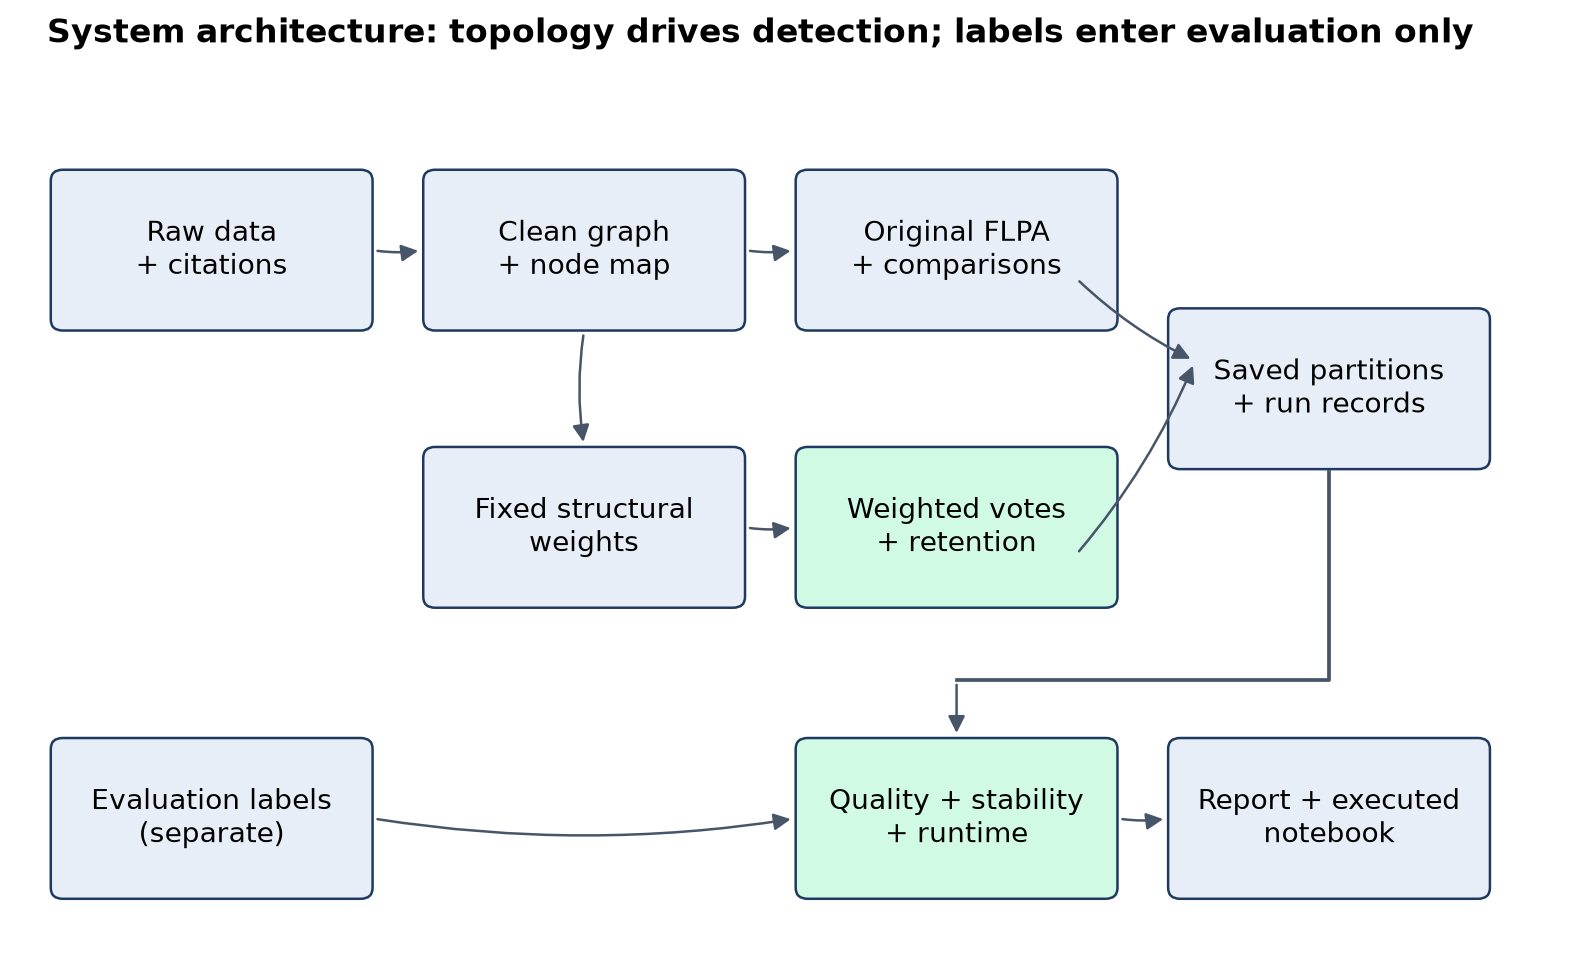

In [28]:
SHORT = {"flpa_original": "B0", "c00_unit_random": "C00", "c10_weighted_random": "C10",
         "c01_unit_retain": "C01", "c11_weighted_retain": "C11", "asyn_lpa": "LPA",
         "leiden_modularity": "Leiden", "nx_weighted_flpa": "NX-W"}
NAMES = {"karate": "Karate", "dolphins": "Dolphins", "football": "Football", "email_eu_core": "Email-Eu-core"}
COLORS = dict(zip(METHODS, ["#34495e", "#94a3b8", "#f59e0b", "#38bdf8", "#0f766e", "#c084fc", "#e85d75", "#8b6f47"]))

def save(fig, path):
    fig.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
    plt.close(fig)


def architecture(path):
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.set(xlim=(-.3, 10), ylim=(0, 6))
    ax.axis("off")
    boxes = {"Raw data\n+ citations": (0, 4.6), "Clean graph\n+ node map": (2.5, 4.6),
             "Original FLPA\n+ comparisons": (5, 4.6), "Fixed structural\nweights": (2.5, 2.6),
             "Weighted votes\n+ retention": (5, 2.6), "Saved partitions\n+ run records": (7.5, 3.6),
             "Evaluation labels\n(separate)": (0, .5), "Quality + stability\n+ runtime": (5, .5),
             "Report + executed\nnotebook": (7.5, .5)}
    for text, (x, y) in boxes.items():
        color = "#d1fae5" if "Weighted" in text or "Quality" in text else "#e8eef7"
        ax.add_patch(FancyBboxPatch((x, y), 2, 1, boxstyle="round,pad=.08", facecolor=color, edgecolor="#1e3a5f"))
        ax.text(x + 1, y + .5, text, ha="center", va="center", fontsize=11)
    edges = [(0, 1), (1, 2), (1, 3), (3, 4), (2, 5), (4, 5), (5, 7), (6, 7), (7, 8)]
    positions = list(boxes.values())
    for a, b in edges:
        x1, y1 = positions[a]; x2, y2 = positions[b]
        if (a, b) == (5, 7):
            ax.plot([8.5, 8.5, 6], [3.5, 2, 2], color="#475569")
            ax.add_patch(FancyArrowPatch((6, 2), (6, 1.58), arrowstyle="-|>", mutation_scale=14, color="#475569"))
            continue
        if abs(y1-y2) < .1:
            start, end = (x1+2.08, y1+.5), (x2-.08, y2+.5)
        elif x1 == x2:
            start, end = (x1+1, y1-.08), (x2+1, y2+1.08)
        else:
            start, end = (x1+1.8, y1+.3), (x2+.1, y2+.7)
        ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=14, color="#475569", connectionstyle="arc3,rad=.08"))
    fig.suptitle("System architecture: topology drives detection; labels enter evaluation only", fontsize=13, fontweight="bold")
    save(fig, path)

output = RUN_ROOT / "reports/figures"
output.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"font.size":10,"axes.spines.top":False,"axes.spines.right":False,
                    "axes.titleweight":"bold","font.family":"DejaVu Sans"})
architecture(output / "architecture.png")
display(Image(filename=str(output / "architecture.png")))

## Step 29. Compare real-network quality, modularity and stability

Create this figure now from this execution's data; its drawing code is included below.

**Inputs:** New summaries, saved predictions and/or the in-memory toy graph.  
**Produces:** real_quality.png

ARI/NMI compare with available references; modularity uses the common original graph. Stability measures repeatability, so inspect it beside quality and largest-group size.

### Code-cell guide 29: Compare real-network quality, modularity and stability

**What and why:** Create this figure now from this execution's data; its drawing code is included below.

**Inputs:** New summaries, saved predictions and/or the in-memory toy graph.

**Outputs and downstream use:** real_quality.png

ARI/NMI compare with available references; modularity uses the common original graph. Stability measures repeatability, so inspect it beside quality and largest-group size.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

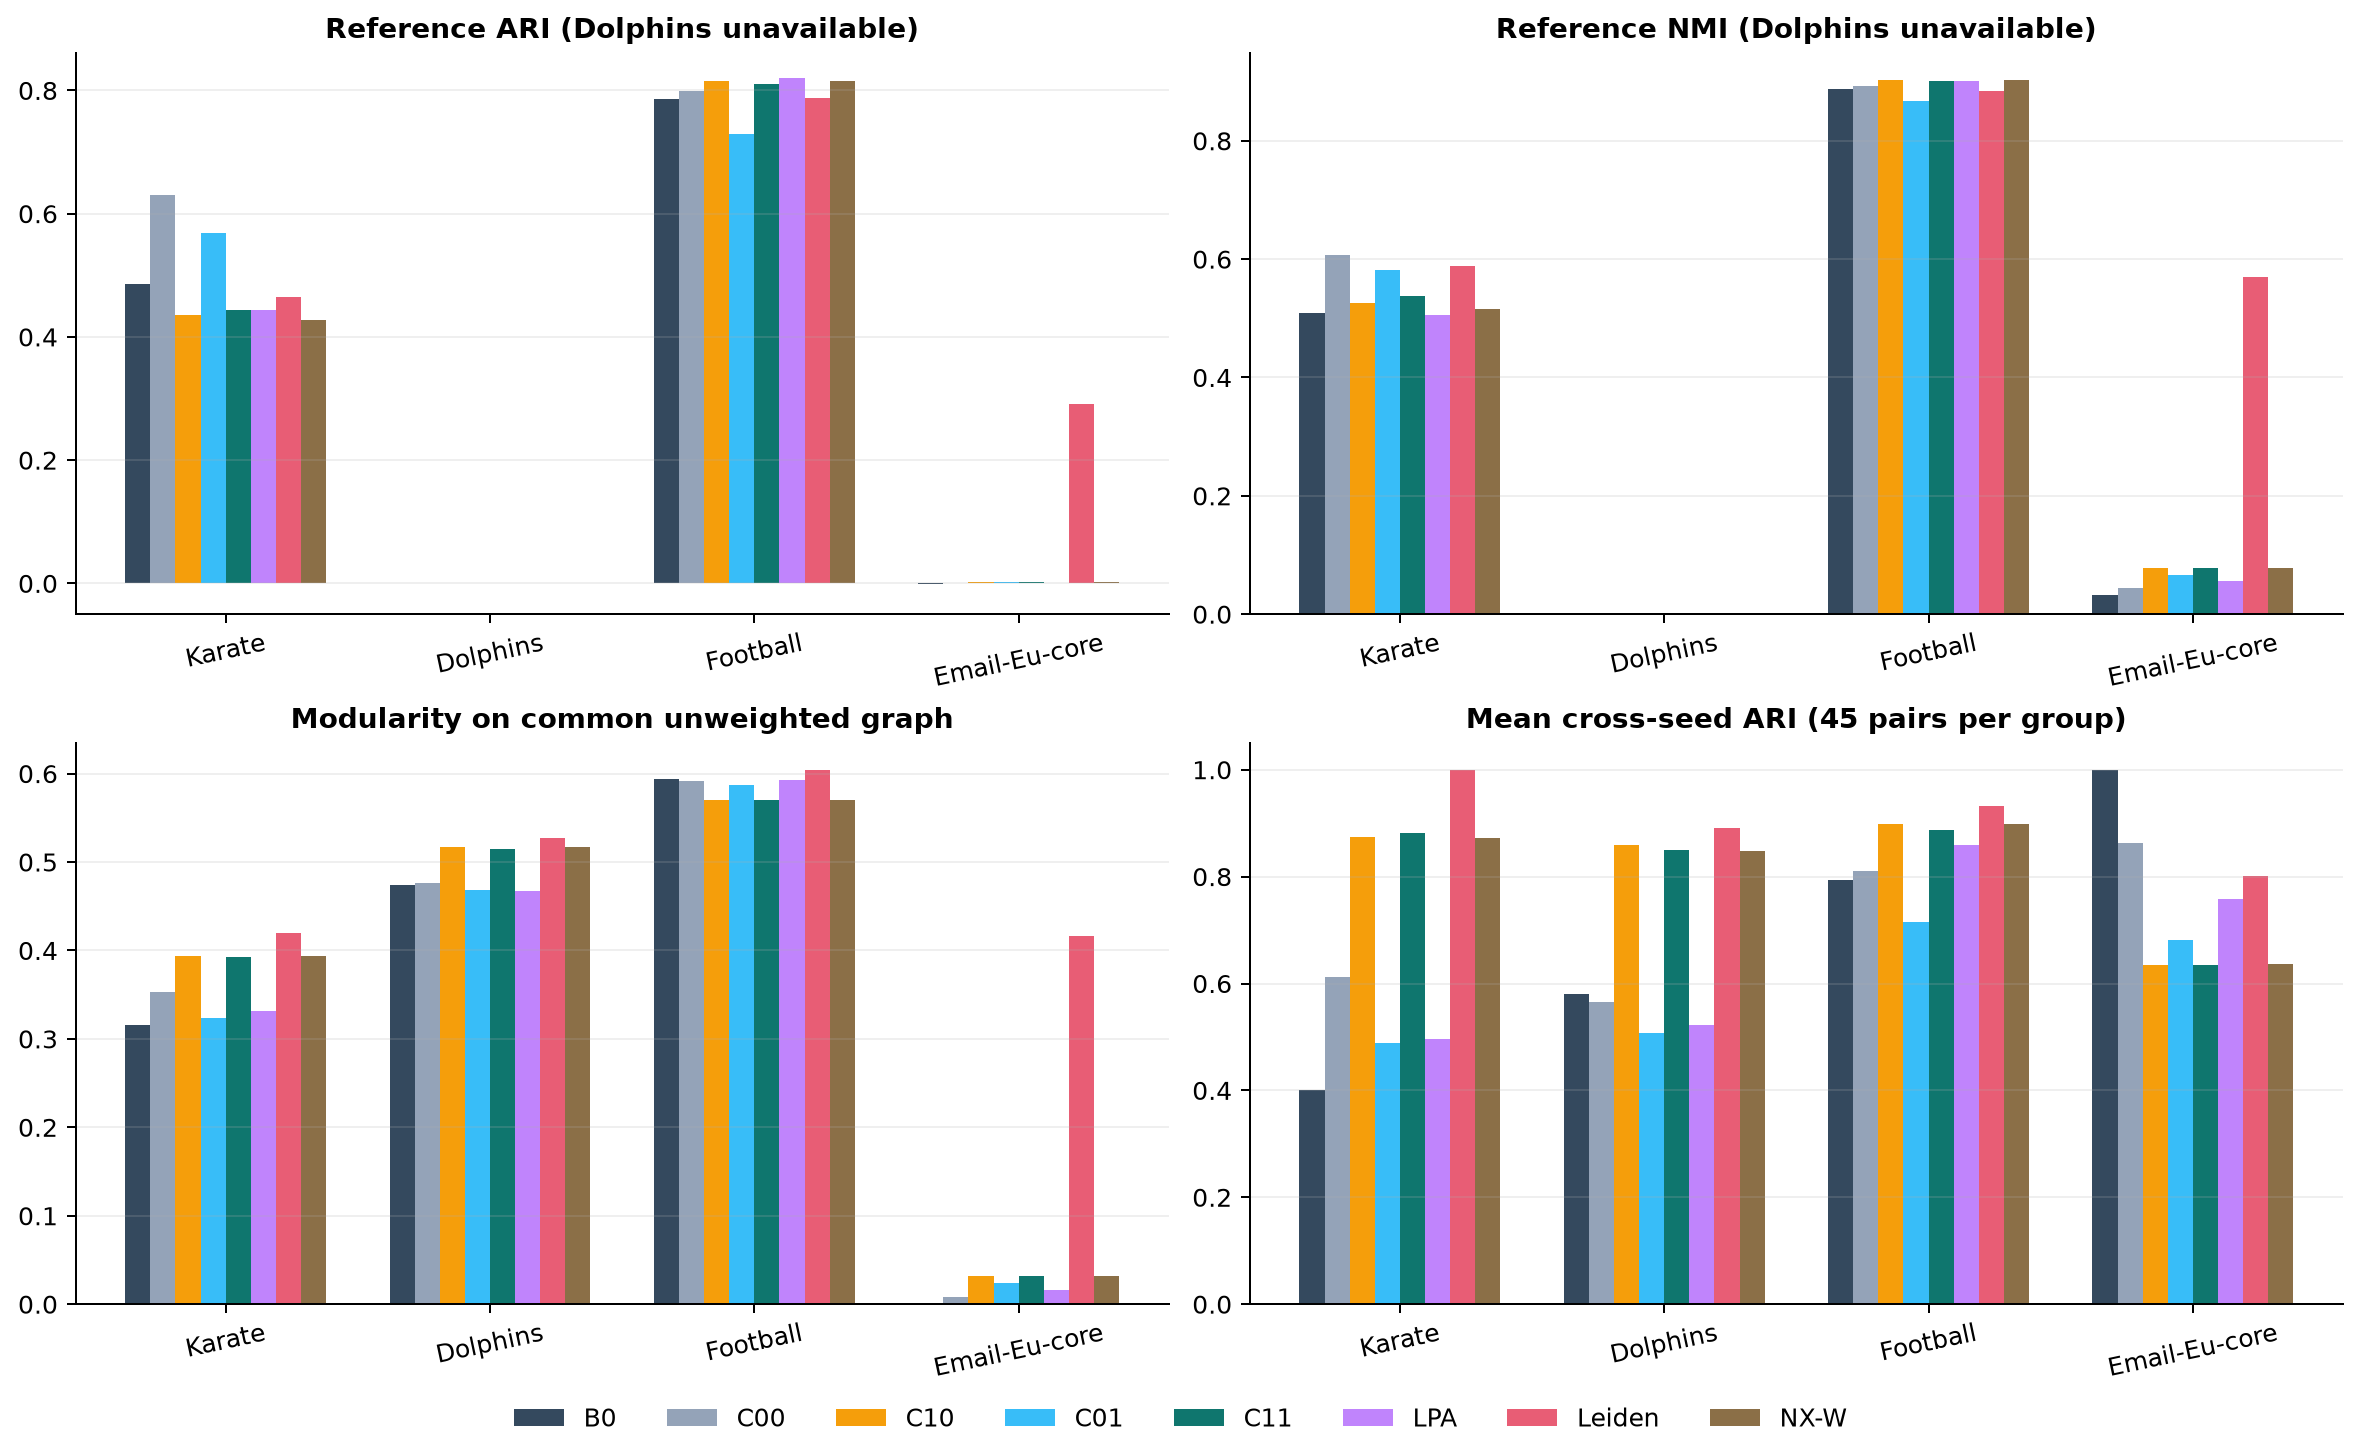

In [29]:
datasets = list(NAMES)
x = np.arange(len(datasets)); width = .095
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")
datasets = list(NAMES)
x = np.arange(len(datasets)); width = .095
for ax, (metric, title) in zip(axes.flat, [("ari", "Reference ARI (Dolphins unavailable)"), ("nmi", "Reference NMI (Dolphins unavailable)"),
                                          ("modularity", "Modularity on common unweighted graph"), ("stability", "Mean cross-seed ARI (45 pairs per group)")]):
    for i, method in enumerate(METHODS):
        rows = real[real.method == method].set_index("dataset_id").reindex(datasets)
        values = rows[metric + "_mean"]
        ax.bar(x + (i - 3.5)*width, values, width, color=COLORS[method], label=SHORT[method])
    ax.set_xticks(x, [NAMES[d] for d in datasets], rotation=12)
    ax.set_title(title, fontsize=11); ax.set_ylim(bottom=-.05 if metric == "ari" else 0)
    ax.grid(axis="y", alpha=.2)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=8, frameon=False)
save(fig, output / "real_quality.png")

display(Image(filename=str(output / "real_quality.png")))

## Step 30. Plot the measured runtime components

Create this figure now from this execution's data; its drawing code is included below.

**Inputs:** New summaries, saved predictions and/or the in-memory toy graph.  
**Produces:** runtime_breakdown.png

Preparation, backend conversion and detector costs are measured separately. Component medians need not sum to the median total. Python/compiled comparisons and tiny-graph overhead limit speed claims.

### Code-cell guide 30: Plot the measured runtime components

**What and why:** Create this figure now from this execution's data; its drawing code is included below.

**Inputs:** New summaries, saved predictions and/or the in-memory toy graph.

**Outputs and downstream use:** runtime_breakdown.png

Preparation, backend conversion and detector costs are measured separately. Component medians need not sum to the median total. Python/compiled comparisons and tiny-graph overhead limit speed claims.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

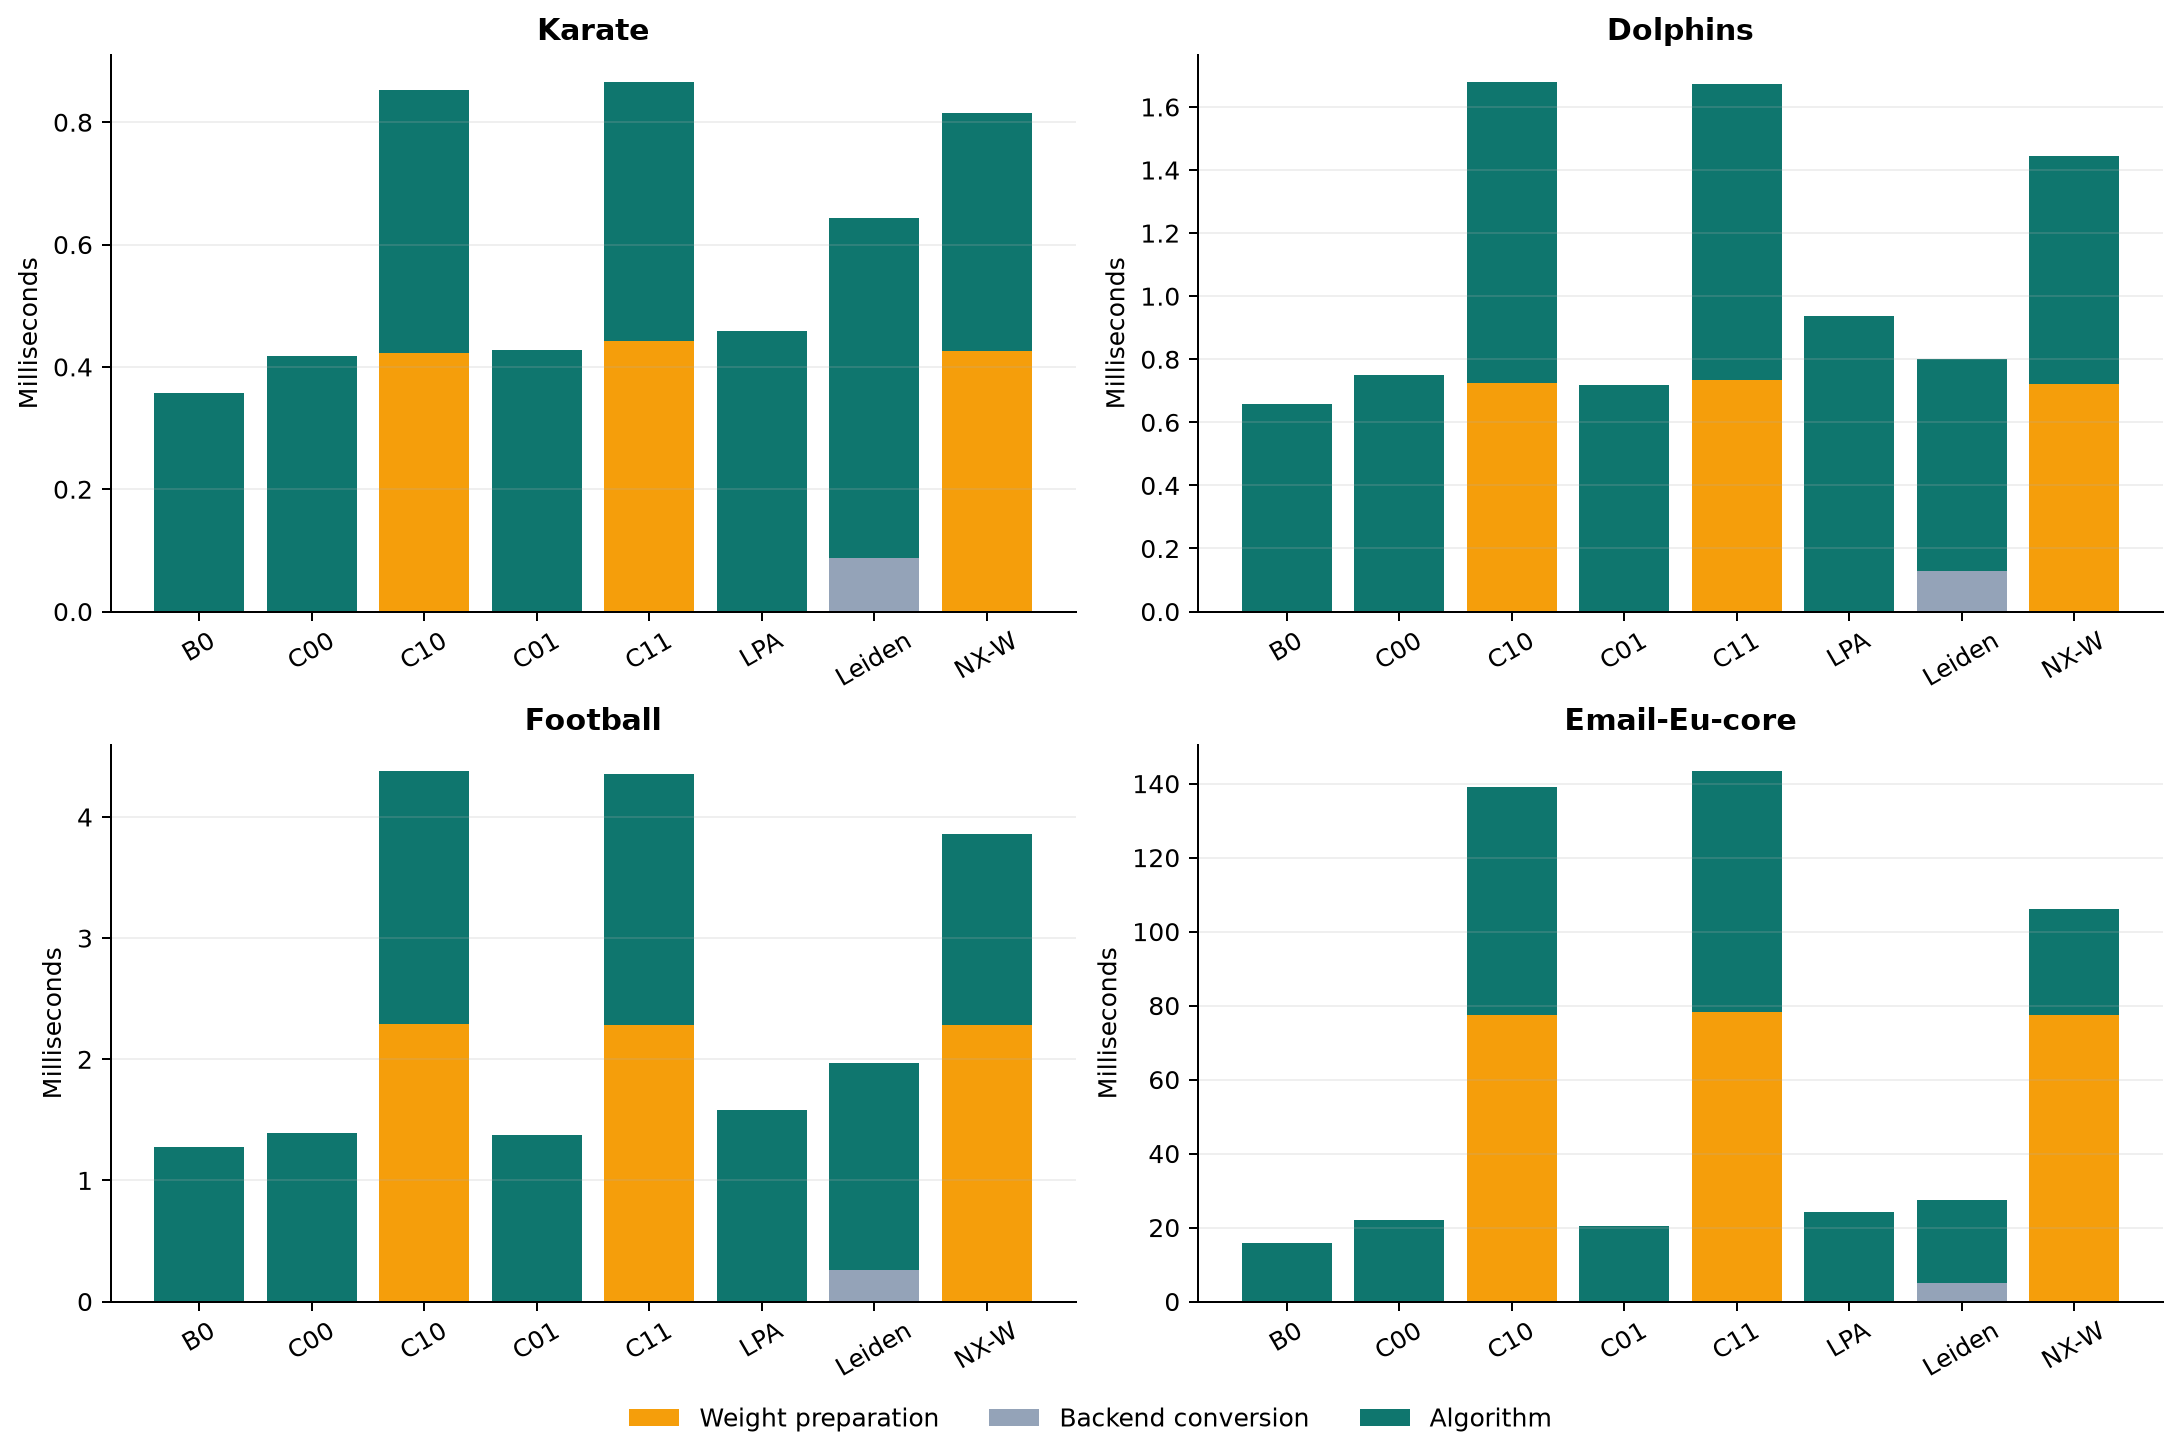

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
for ax, dataset in zip(axes.flat, datasets):
    rows = real[real.dataset_id == dataset].set_index("method").reindex(METHODS)
    preparation = rows.feature_prepare_s_median.to_numpy() * 1000
    conversion = rows.conversion_s_median.to_numpy() * 1000
    algorithm = rows.algorithm_s_median.to_numpy() * 1000
    ax.bar(range(8), preparation, label="Weight preparation", color="#f59e0b")
    ax.bar(range(8), conversion, bottom=preparation, label="Backend conversion", color="#94a3b8")
    ax.bar(range(8), algorithm, bottom=preparation+conversion, label="Algorithm", color="#0f766e")
    ax.set_xticks(range(8), [SHORT[m] for m in METHODS], rotation=30)
    ax.set_ylabel("Milliseconds"); ax.set_title(NAMES[dataset]); ax.grid(axis="y", alpha=.2)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
save(fig, output / "runtime_breakdown.png")

display(Image(filename=str(output / "runtime_breakdown.png")))

## Step 31. Plot the distribution of cross-seed stability

Create this figure now from this execution's data; its drawing code is included below.

**Inputs:** New summaries, saved predictions and/or the in-memory toy graph.  
**Produces:** stability.png

Each boxplot uses the 45 dependent ARI pair comparisons from ten seeds. Consistent collapse can look perfectly stable.

### Code-cell guide 31: Plot the distribution of cross-seed stability

**What and why:** Create this figure now from this execution's data; its drawing code is included below.

**Inputs:** New summaries, saved predictions and/or the in-memory toy graph.

**Outputs and downstream use:** stability.png

Each boxplot uses the 45 dependent ARI pair comparisons from ten seeds. Consistent collapse can look perfectly stable.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

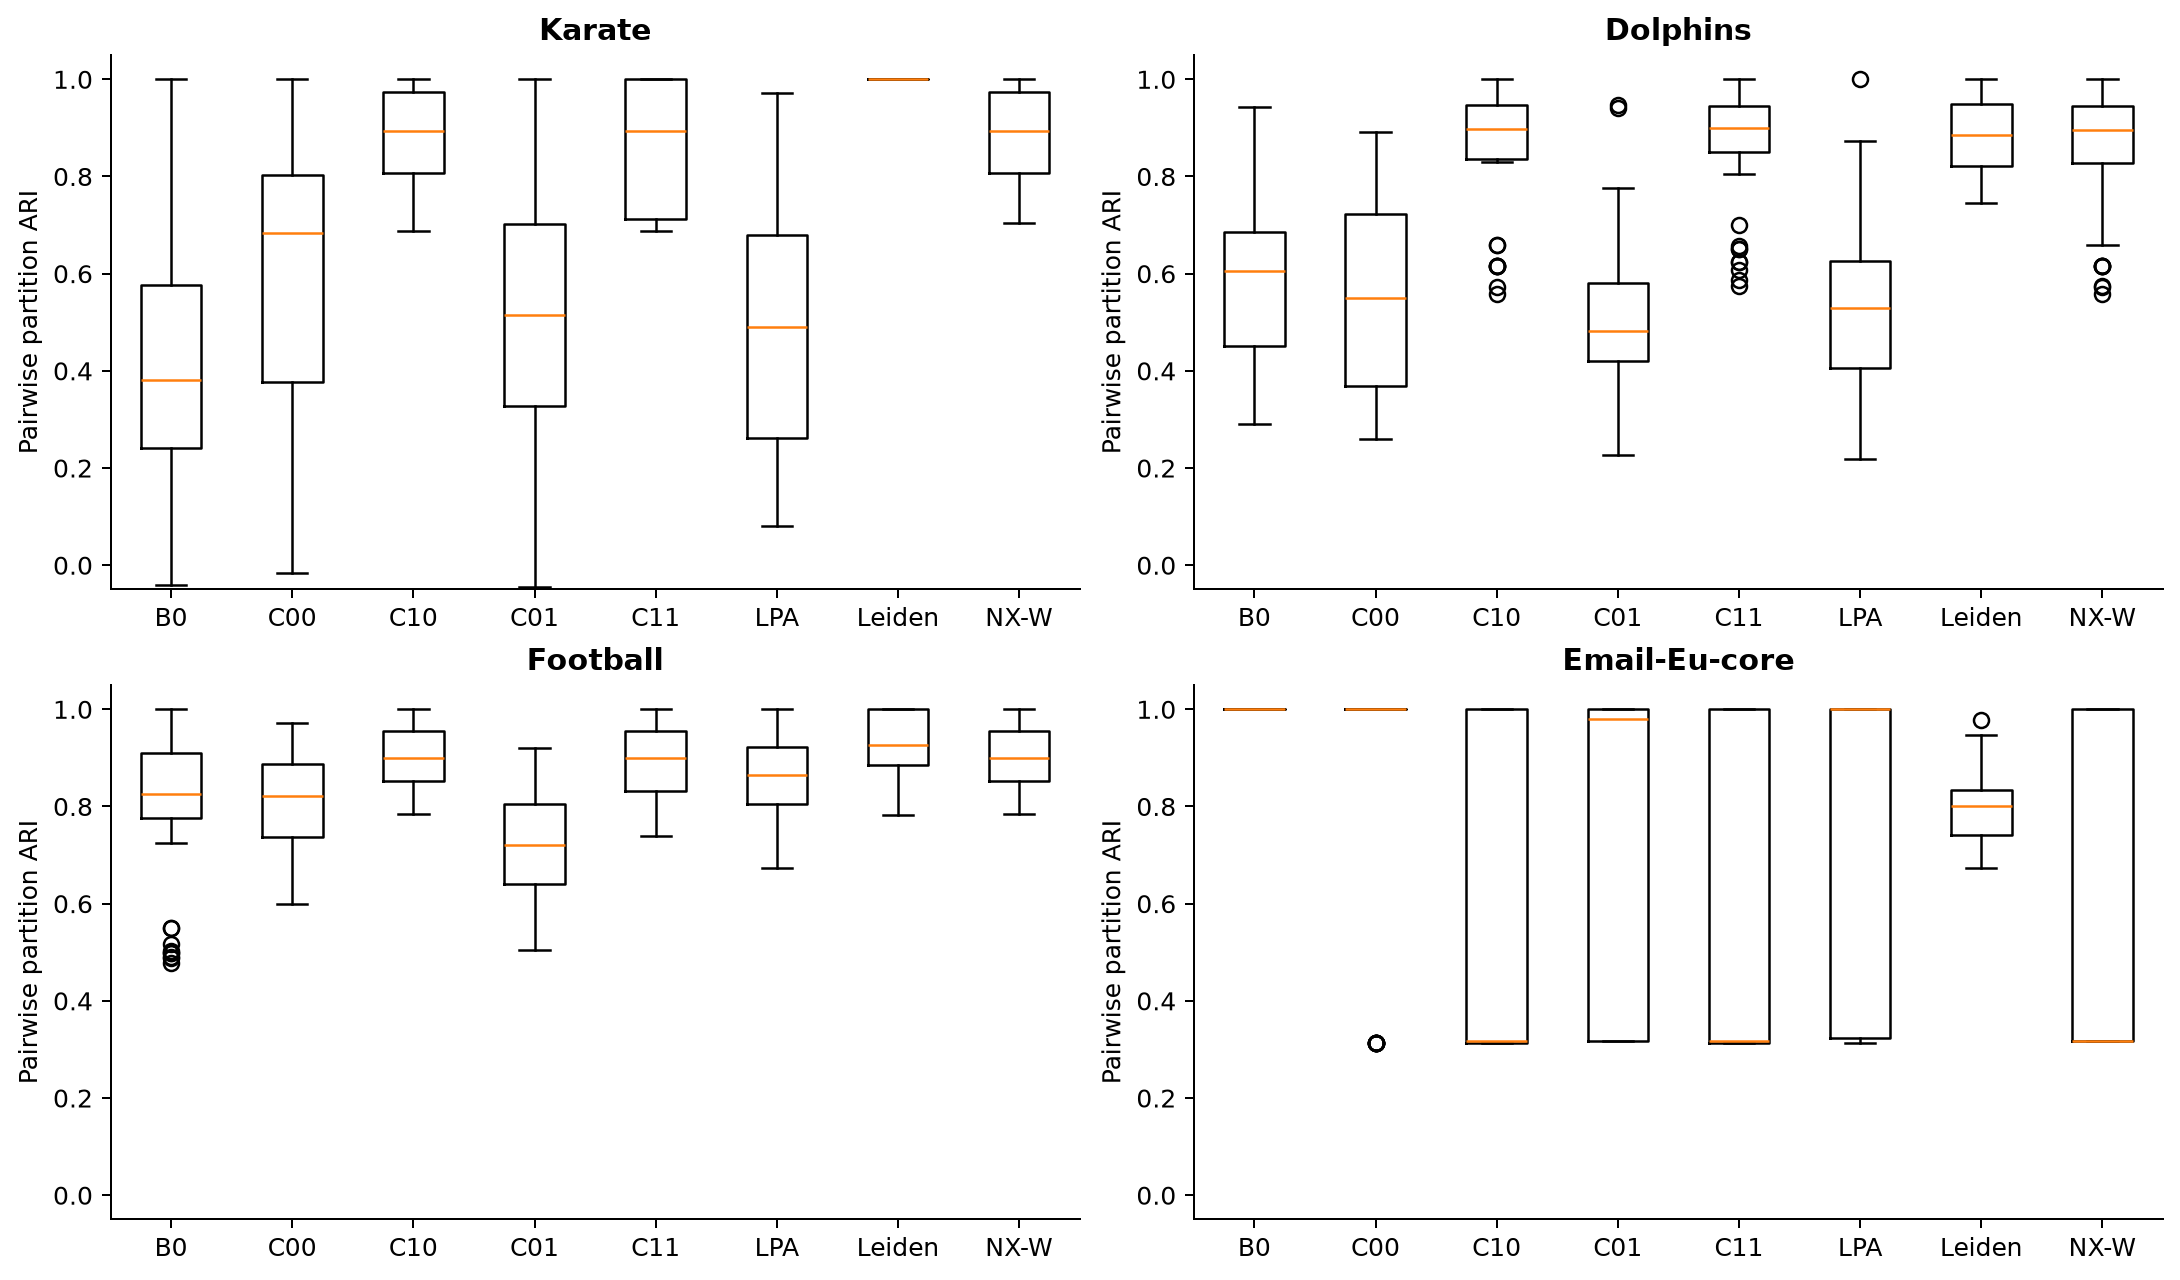

In [31]:
pairs = pd.read_csv(RUN_ROOT / "results" / "summaries" / "stability_pairs.csv")
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for ax, dataset in zip(axes.flat, datasets):
    groups = [pairs[(pairs.role == "real") & (pairs.dataset_id == dataset) & (pairs.method == method)].stability_ari.to_numpy() for method in METHODS]
    ax.boxplot(groups, tick_labels=[SHORT[m] for m in METHODS], showfliers=True)
    ax.set_title(NAMES[dataset]); ax.set_ylim(-.05, 1.05); ax.set_ylabel("Pairwise partition ARI")
save(fig, output / "stability.png")

display(Image(filename=str(output / "stability.png")))

## Step 32. Draw actual predicted communities using a common layout

Create this figure now from this execution's data; its drawing code is included below.

**Inputs:** New summaries, saved predictions and/or the in-memory toy graph.  
**Produces:** communities.png

Each graph gets one fixed spring layout so visual positions do not change across methods. These are seed-0 examples, while the metric tables summarise ten seeds. Email remains in the quantitative tables.

### Code-cell guide 32: Draw actual predicted communities using a common layout

**What and why:** Create this figure now from this execution's data; its drawing code is included below.

**Inputs:** New summaries, saved predictions and/or the in-memory toy graph.

**Outputs and downstream use:** communities.png

Each graph gets one fixed spring layout so visual positions do not change across methods. These are seed-0 examples, while the metric tables summarise ten seeds. Email remains in the quantitative tables.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

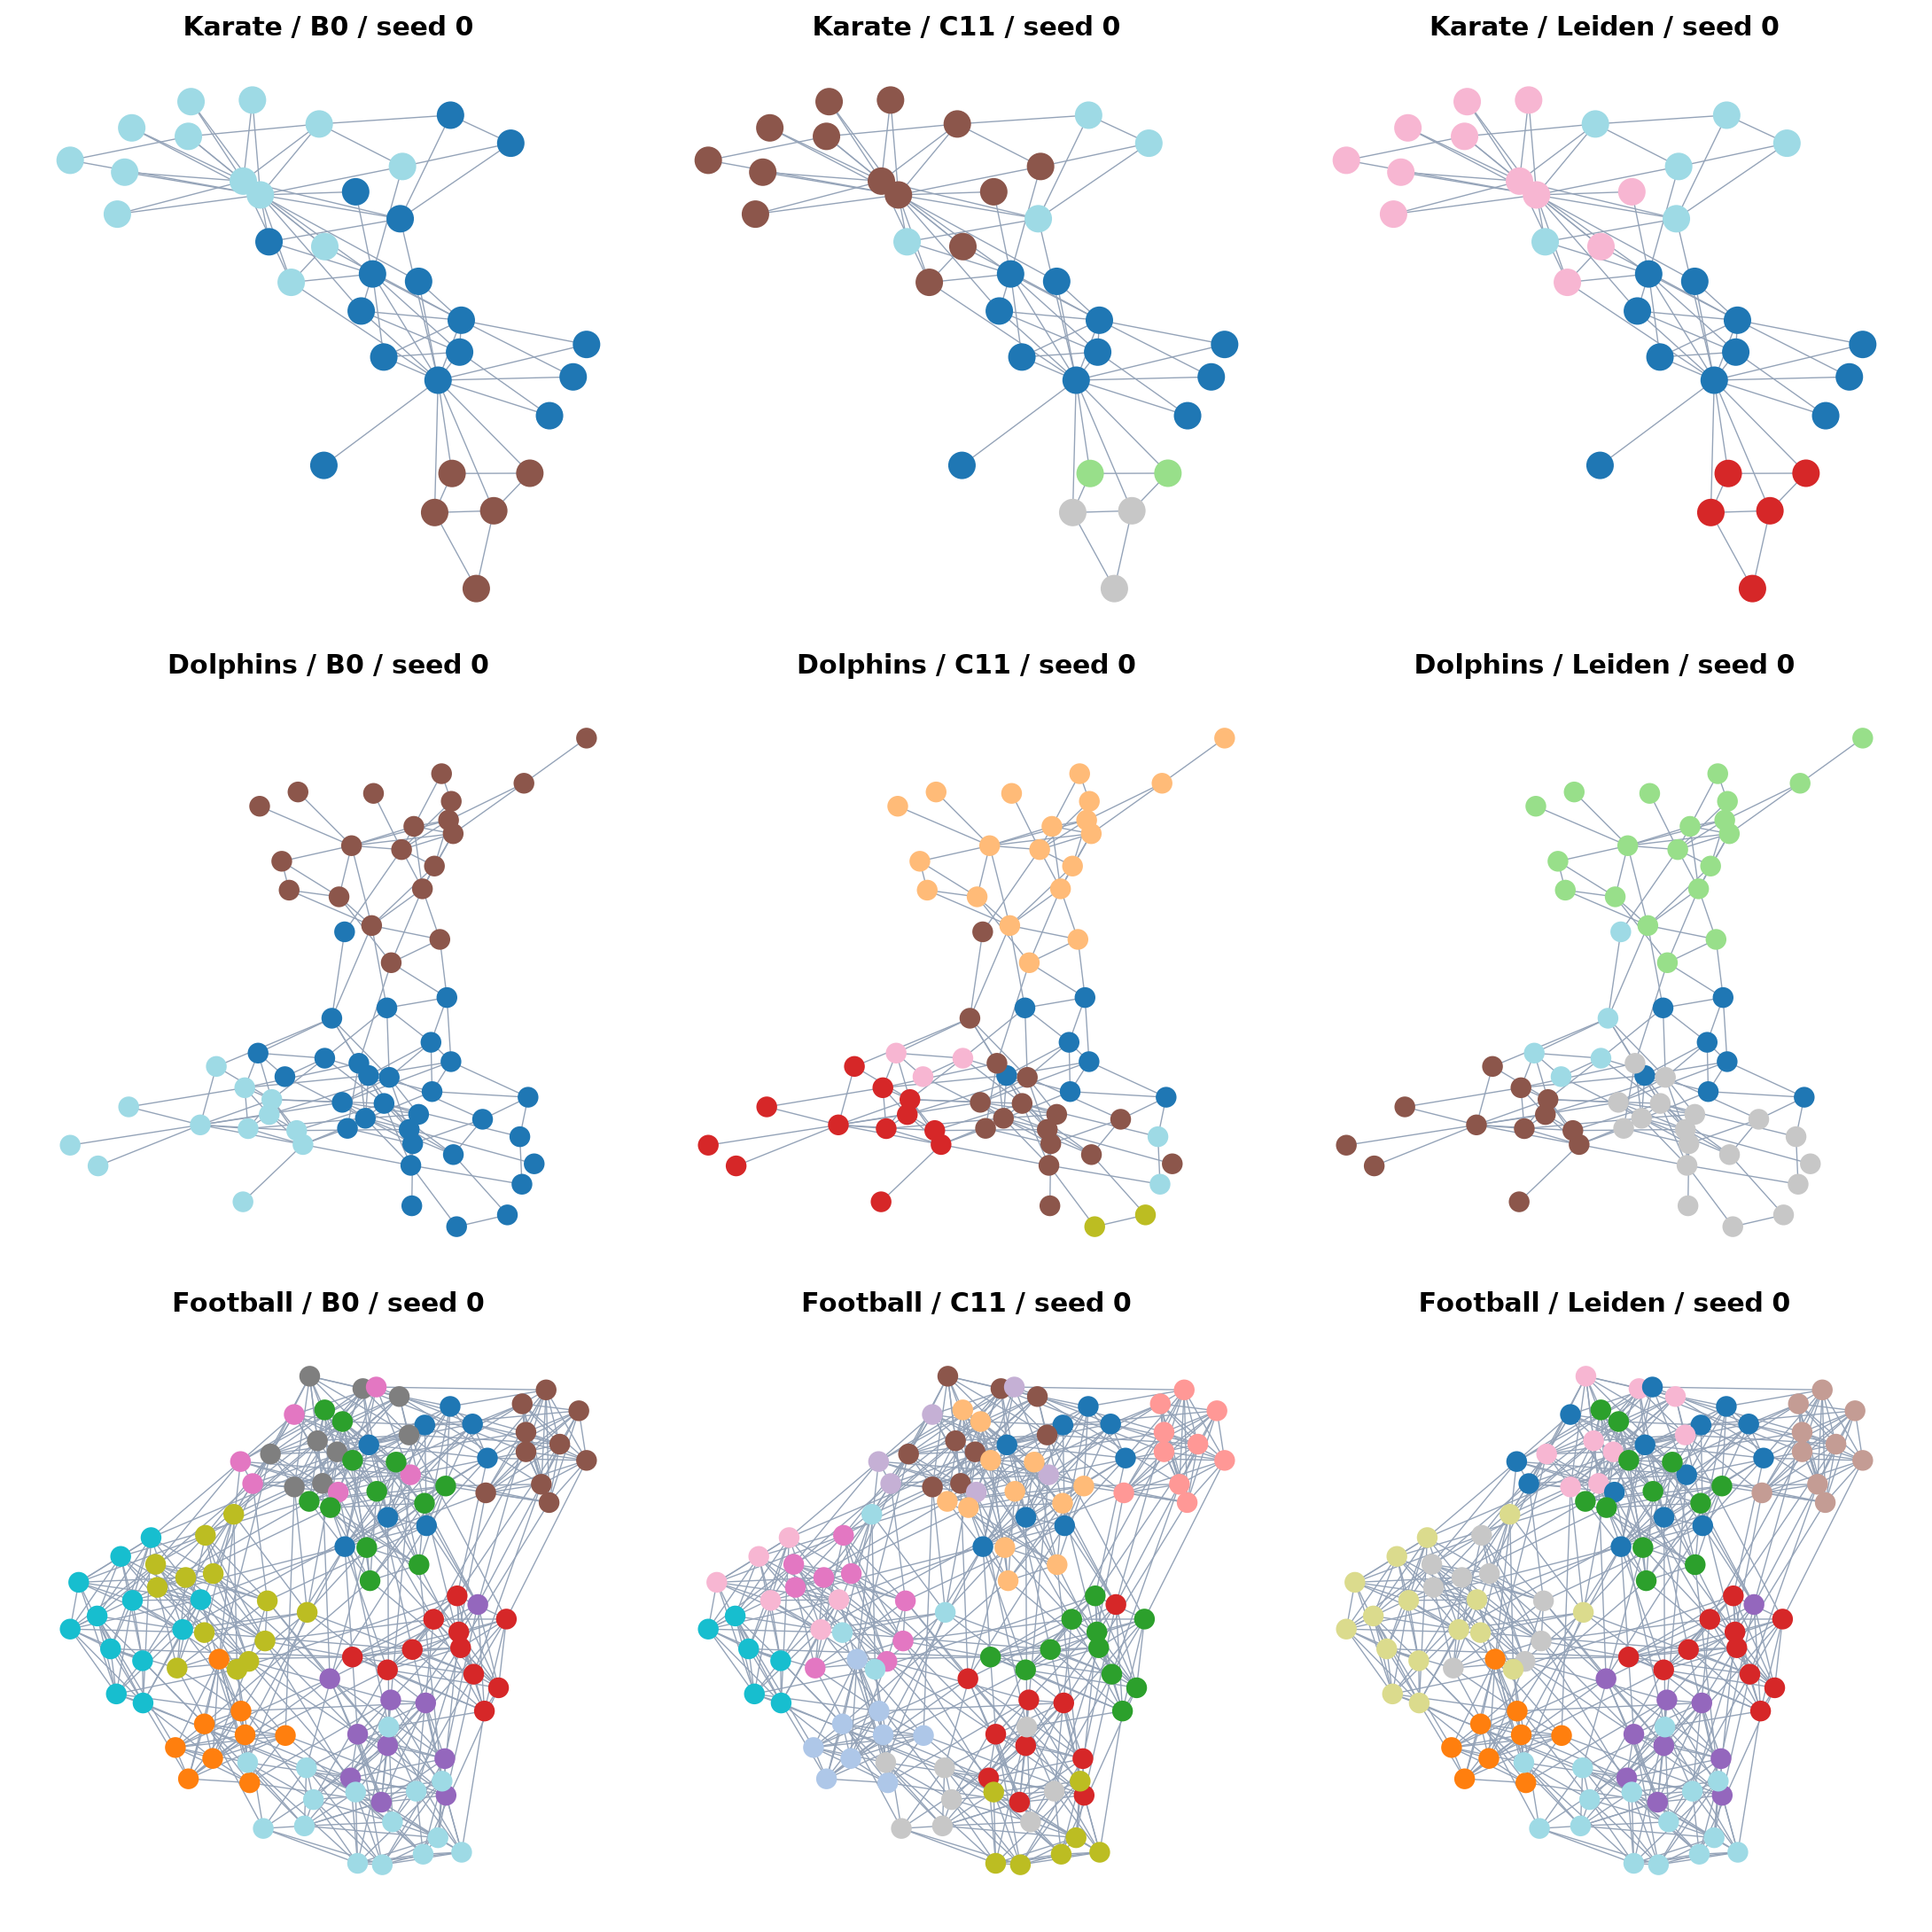

In [32]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12), layout="constrained")
for row, dataset in enumerate(["karate", "dolphins", "football"]):
    item = load_prepared(RUN_ROOT, dataset)
    pos = nx.spring_layout(item.graph, seed=1947, iterations=100)
    for column, method in enumerate(["flpa_original", "c11_weighted_retain", "leiden_modularity"]):
        record = real[(real.dataset_id == dataset) & (real.method == method)].iloc[0]
        path = RUN_ROOT / "results" / "runs" / record.attempt / f"{dataset}__{method}__seed0" / "partition.csv"
        partition = pd.read_csv(path).set_index("internal_id").community_id.to_dict()
        ax = axes[row, column]
        nx.draw_networkx(item.graph, pos=pos, ax=ax, with_labels=False, node_size=70 if dataset != "karate" else 130,
                         node_color=[partition[u] for u in item.graph], cmap=plt.cm.tab20,
                         edge_color="#94a3b8", width=.55)
        ax.set_title(f"{NAMES[dataset]} / {SHORT[method]} / seed 0"); ax.axis("off")
save(fig, output / "communities.png")

display(Image(filename=str(output / "communities.png")))

## Step 33. Plot the synthetic stress test

Create this figure now from this execution's data; its drawing code is included below.

**Inputs:** New summaries, saved predictions and/or the in-memory toy graph.  
**Produces:** synthetic_stress.png

The plots average the three graph-instance summaries at each mixing level. Error bars describe variation across those graphs; they are not significance-test results.

### Code-cell guide 33: Plot the synthetic stress test

**What and why:** Create this figure now from this execution's data; its drawing code is included below.

**Inputs:** New summaries, saved predictions and/or the in-memory toy graph.

**Outputs and downstream use:** synthetic_stress.png

The plots average the three graph-instance summaries at each mixing level. Error bars describe variation across those graphs; they are not significance-test results.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

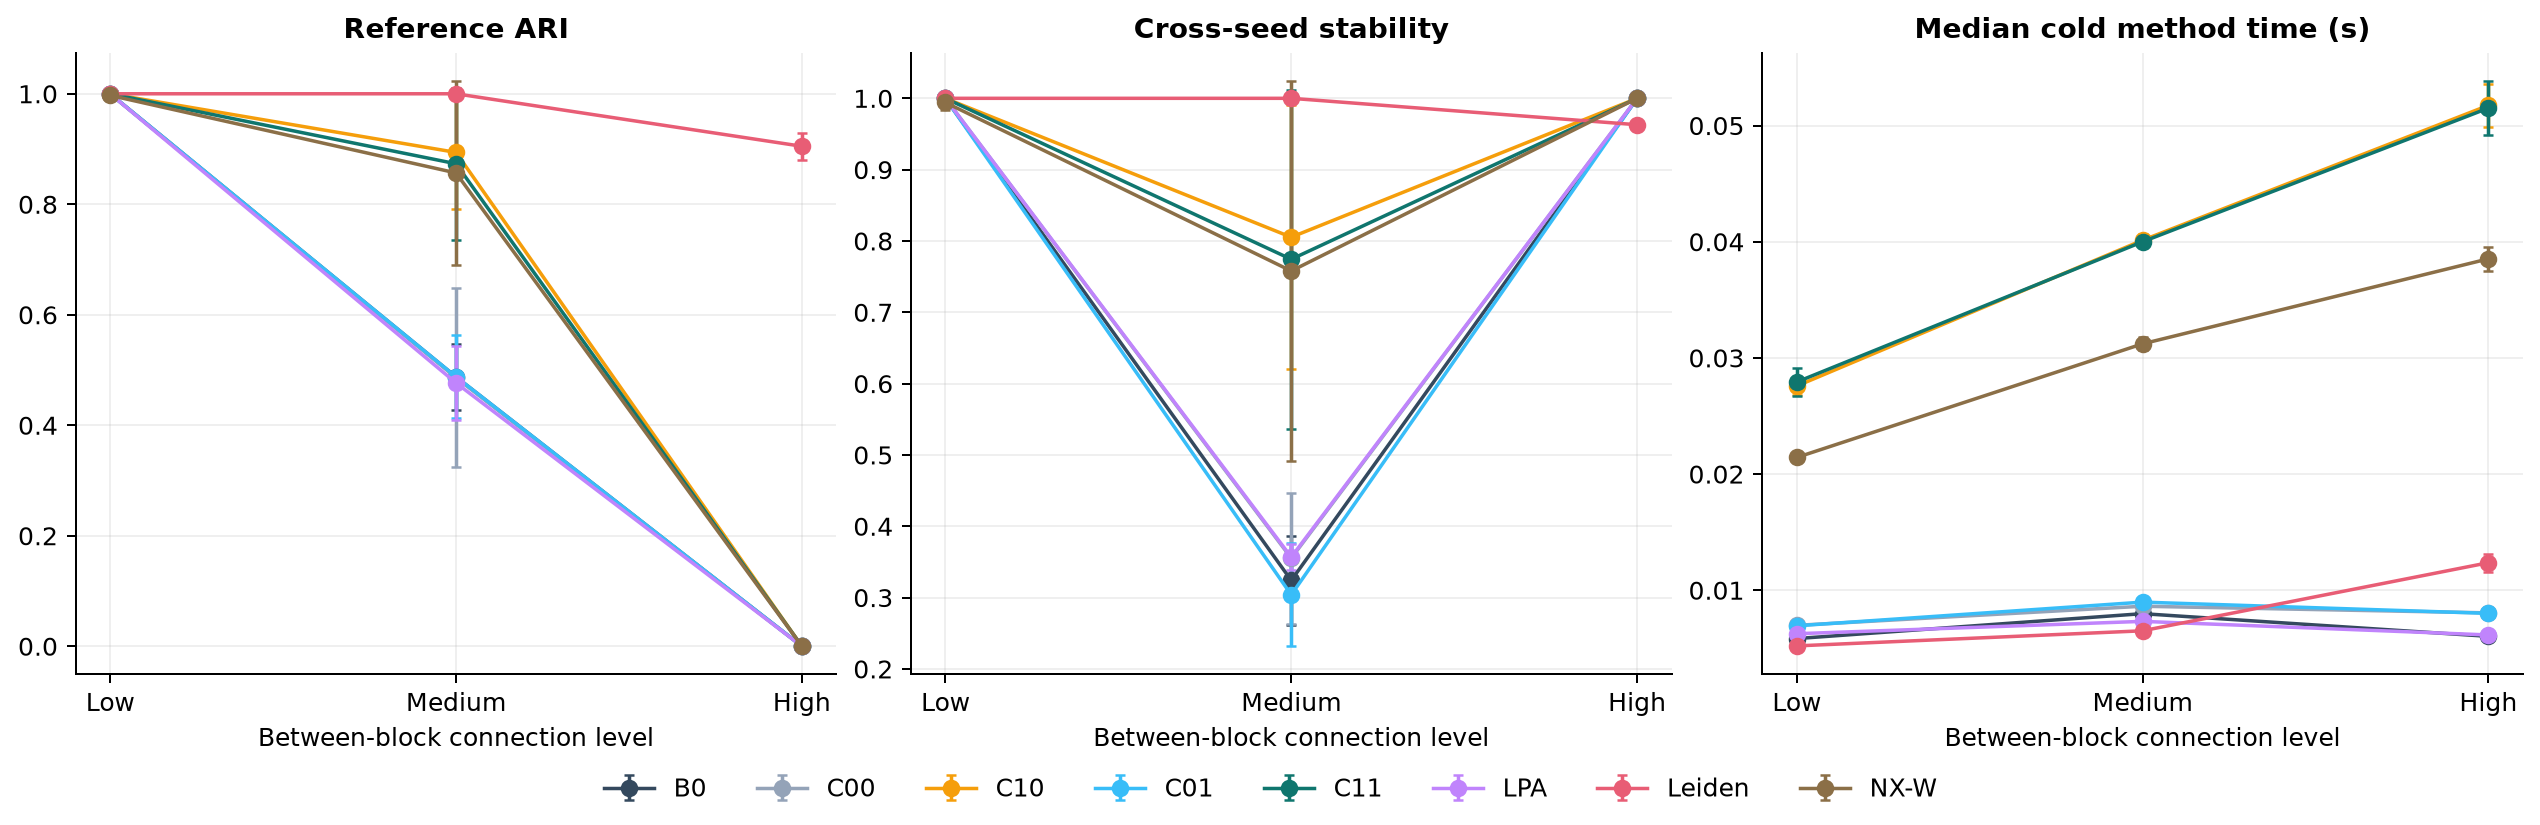

In [33]:
test = summary[summary.role == "test"].copy()
if len(test):
    test["mixing"] = test.dataset_id.str.extract(r"test_sbm_(low|medium|high)_")[0]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout="constrained")
    for ax, metric, title in zip(axes, ["ari_mean", "stability_mean", "method_total_s_median"],
                                 ["Reference ARI", "Cross-seed stability", "Median cold method time (s)"]):
        for method in METHODS:
            grouped = test[test.method == method].groupby("mixing")[metric]
            means = grouped.mean().reindex(["low", "medium", "high"])
            std = grouped.std().reindex(["low", "medium", "high"])
            ax.errorbar([0, 1, 2], means, yerr=std, label=SHORT[method], color=COLORS[method], marker="o", capsize=2, linewidth=1.4)
        ax.set_xticks([0, 1, 2], ["Low", "Medium", "High"])
        ax.set_xlabel("Between-block connection level"); ax.set_title(title, fontsize=11); ax.grid(alpha=.2)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=8, frameon=False)
    save(fig, output / "synthetic_stress.png")

display(Image(filename=str(output / "synthetic_stress.png")))

## Step 34. Draw the structural-weight mechanism

Create this figure now from this execution's data; its drawing code is included below.

**Inputs:** New summaries, saved predictions and/or the in-memory toy graph.  
**Produces:** weight_example.png

The illustrative graph has two triangles joined by a bridge. This plot uses lambda 1 for visible edge arithmetic, whereas final experiments use the selected lambda.

### Code-cell guide 34: Draw the structural-weight mechanism

**What and why:** Create this figure now from this execution's data; its drawing code is included below.

**Inputs:** New summaries, saved predictions and/or the in-memory toy graph.

**Outputs and downstream use:** weight_example.png

The illustrative graph has two triangles joined by a bridge. This plot uses lambda 1 for visible edge arithmetic, whereas final experiments use the selected lambda.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

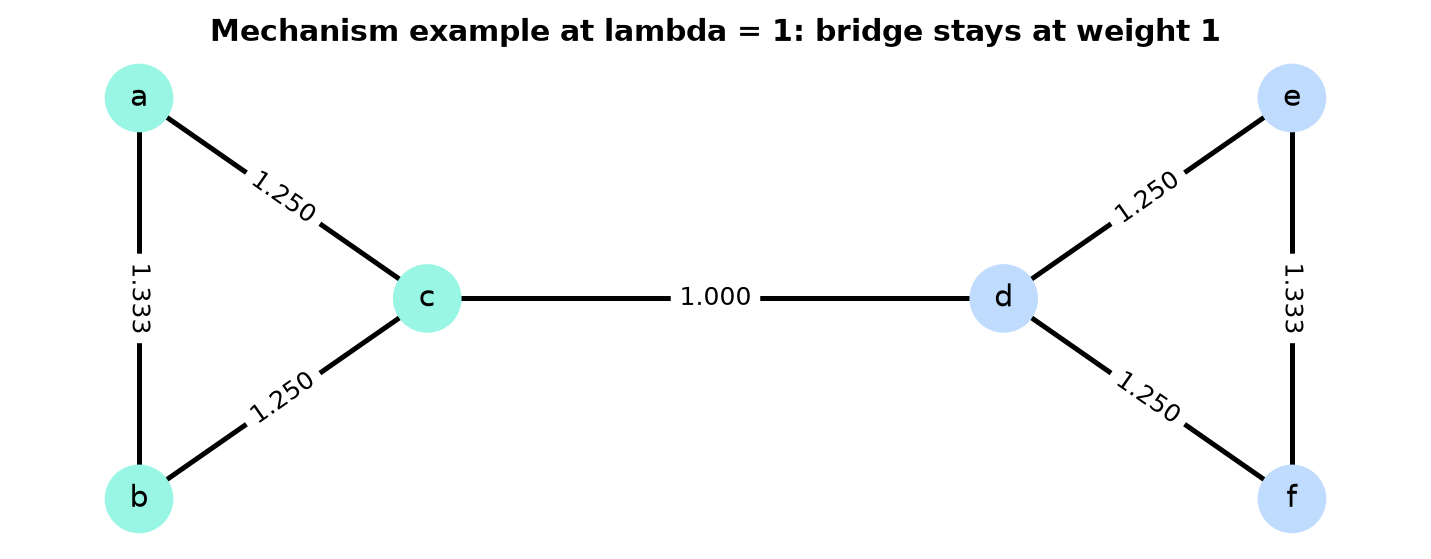

In [34]:
graph = nx.Graph([(0, 1), (1, 2), (0, 2), (3, 4), (4, 5), (3, 5), (2, 3)])
weighted = apply_weights(graph, edge_similarity(graph), 1)
pos = {0: (-1, 1), 1: (-1, -1), 2: (0, 0), 3: (2, 0), 4: (3, 1), 5: (3, -1)}
fig, ax = plt.subplots(figsize=(10, 3.5))
nx.draw_networkx(graph, pos, ax=ax, labels=dict(enumerate("abcdef")), node_color=["#99f6e4"]*3+["#bfdbfe"]*3,
                 node_size=700, width=2)
nx.draw_networkx_edge_labels(graph, pos, ax=ax,
                            edge_labels={(u, v): f"{weighted[u][v]['structural_weight']:.3f}" for u, v in graph.edges})
ax.set_title("Mechanism example at lambda = 1: bridge stays at weight 1"); ax.axis("off")
save(fig, output / "weight_example.png")

display(Image(filename=str(output / "weight_example.png")))

## Step 35. Display paired ablations and synthetic condition summaries

Summarise the controlled comparisons and failure cases after inspecting the underlying graphs and measurements.

**Inputs:** Fresh paired_differences.csv and method_summary rows.  
**Produces:** Paired changes and a low/medium/high table.

Positive ARI difference favours treatment on that metric; positive time difference means slower treatment. Reference agreement, modularity and stability can disagree. At high mixing, a one-group answer can be both wrong and stable.

### Code-cell guide 35: Display paired ablations and synthetic condition summaries

**What and why:** Summarise the controlled comparisons and failure cases after inspecting the underlying graphs and measurements.

**Inputs:** Fresh paired_differences.csv and method_summary rows.

**Outputs and downstream use:** Paired changes and a low/medium/high table.

Positive ARI difference favours treatment on that metric; positive time difference means slower treatment. Reference agreement, modularity and stability can disagree. At high mixing, a one-group answer can be both wrong and stable.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [35]:
differences = pd.read_csv(RUN_ROOT / "results/summaries/paired_differences.csv")
display(differences[differences.dataset_id.isin(real_ids)][[
    "dataset_id","interpretation","paired_runs","ari_difference_mean","modularity_difference_mean","method_total_s_difference_mean"]].round(6))
test = summary[summary.role.eq("test")].copy()
test["level"] = test.dataset_id.str.split("_").str[2]
display(test.groupby(["level","method"])[["ari_mean","stability_mean","largest_fraction_mean"]].mean().round(4))

,dataset_id,interpretation,paired_runs,ari_difference_mean,modularity_difference_mean,method_total_s_difference_mean
0,dolphins,scheduler,10,NaN,0.002128,0.000112
1,dolphins,weights_without_retention,10,NaN,0.041381,0.000936
2,dolphins,retention_without_weights,10,NaN,-0.007907,-0.000050
3,dolphins,weights_with_retention,10,NaN,0.046118,0.000940
4,dolphins,complete_design,10,NaN,0.040339,0.001003
5,email_eu_core,scheduler,10,0.000923,0.007946,0.005894
6,email_eu_core,weights_without_retention,10,0.002780,0.023817,0.129307
7,email_eu_core,retention_without_weights,10,0.001705,0.015838,-0.000096
8,email_eu_core,weights_with_retention,10,0.001070,0.007990,0.125893
9,email_eu_core,complete_design,10,0.003698,0.031774,0.131691


ari_mean  stability_mean  largest_fraction_mean
level  method                                                              
high   asyn_lpa               0.0000          1.0000                 1.0000
       c00_unit_random        0.0000          1.0000                 1.0000
       c01_unit_retain        0.0000          1.0000                 1.0000
       c10_weighted_random    0.0000          1.0000                 1.0000
       c11_weighted_retain    0.0000          1.0000                 1.0000
       flpa_original          0.0000          1.0000                 1.0000
       leiden_modularity      0.9050          0.9630                 0.2598
       nx_weighted_flpa       0.0000          1.0000                 1.0000
low    asyn_lpa               1.0000          1.0000                 0.2500
       c00_unit_random        1.0000          1.0000                 0.2500
       c01_unit_retain        1.0000          1.0000                 0.2500
       c10_weighted_random    1.0000          1.0000                 0.2500
       c11_weighted_retain    1.0000          1.0000                 0.2500
       flpa_original          1.0000          1.0000                 0.2500
       leiden_modularity      1.0000          1.0000                 0.2500
       nx_weighted_flpa       0.9971          0.9942                 0.2500
medium asyn_lpa               0.4767          0.3568                 0.6447
       c00_unit_random        0.4861          0.3553                 0.6372
       c01_unit_retain        0.4878          0.3039                 0.6377
       c10_weighted_random    0.8939          0.8053                 0.3352
       c11_weighted_retain    0.8733          0.7743                 0.3439
       flpa_original          0.4875          0.3241                 0.6374
       leiden_modularity      1.0000          1.0000                 0.2500
       nx_weighted_flpa       0.8567          0.7579                 0.3606

## Step 36. Record the research-paper evidence

Keep the methods and prior-art trail with the complete implementation, including the distinction between reviewed work and implemented code.

**Inputs:** The embedded ten-paper bibliography.  
**Produces:** A publication table with direct DOI links.

R01 supplies FLPA; related weighting/embedding papers inform the comparison and novelty assessment. The literature is not the detector's training data. Full PDFs and reviews remain additional submission evidence; no PDF file is required to execute this notebook.

### Code-cell guide 36: Record the research-paper evidence

**What and why:** Keep the methods and prior-art trail with the complete implementation, including the distinction between reviewed work and implemented code.

**Inputs:** The embedded ten-paper bibliography.

**Outputs and downstream use:** A publication table with direct DOI links.

R01 supplies FLPA; related weighting/embedding papers inform the comparison and novelty assessment. The literature is not the detector's training data. Full PDFs and reviews remain additional submission evidence; no PDF file is required to execute this notebook.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [36]:
bibliography = [{'id': 'R01', 'title': 'Large network community detection by fast label propagation', 'doi': '10.1038/s41598-023-29610-z', 'authors': 'Vincent A. Traag; Lovro Šubelj', 'journal': 'Scientific Reports', 'year': 2023, 'article_type': 'journal-article', 'source_url': 'https://www.nature.com/articles/s41598-023-29610-z', 'doi_url': 'https://doi.org/10.1038/s41598-023-29610-z', 'pages': 11, 'pdf': 'research/papers/R01.pdf', 'source_text': 'research/sources/R01/full_text.txt', 'sha256': 'da7f79cbe958d456d14c2817ddd420fbdcb02f54fe672d0be7c133ba646865ad', 'retrieved_utc': '2026-10-26T14:50:57.259312+00:00'}, {'id': 'R02', 'title': 'A community partitioning algorithm for cyberspace', 'doi': '10.1038/s41598-023-46556-4', 'authors': 'Kai Qi; Heng Zhang; Yang Zhou; Yifan Liu; Qingxiang Li', 'journal': 'Scientific Reports', 'year': 2023, 'article_type': 'journal-article', 'source_url': 'https://www.nature.com/articles/s41598-023-46556-4', 'doi_url': 'https://doi.org/10.1038/s41598-023-46556-4', 'pages': 12, 'pdf': 'research/papers/R02.pdf', 'source_text': 'research/sources/R02/full_text.txt', 'sha256': '7aa5a77ff793e529cfe5a9a23ff36a4ee27fe0bbf825c32424f95f718d6da564', 'retrieved_utc': '2026-10-26T14:50:52.043852+00:00'}, {'id': 'R03', 'title': 'Iterative embedding and reweighting of complex networks reveals community structure', 'doi': '10.1038/s41598-024-68152-w', 'authors': 'Bianka Kovács; Sadamori Kojaku; Gergely Palla; Santo Fortunato', 'journal': 'Scientific Reports', 'year': 2024, 'article_type': 'journal-article', 'source_url': 'https://www.nature.com/articles/s41598-024-68152-w', 'doi_url': 'https://doi.org/10.1038/s41598-024-68152-w', 'pages': 17, 'pdf': 'research/papers/R03.pdf', 'source_text': 'research/sources/R03/full_text.txt', 'sha256': '23d75f218cb67c97829965ad87c70d8facff6565f60f5d7f589a0420f663cdfa', 'retrieved_utc': '2026-10-26T14:50:59.501724+00:00'}, {'id': 'R04', 'title': 'GATFELPA integrates graph attention networks and enhanced label propagation for robust community detection', 'doi': '10.1038/s41598-024-84962-4', 'authors': 'Feiyi Tang; Junxian Li; Xi Liu; Chao Chang; Luyao Teng', 'journal': 'Scientific Reports', 'year': 2025, 'article_type': 'journal-article', 'source_url': 'https://www.nature.com/articles/s41598-024-84962-4', 'doi_url': 'https://doi.org/10.1038/s41598-024-84962-4', 'pages': 17, 'pdf': 'research/papers/R04.pdf', 'source_text': 'research/sources/R04/full_text.txt', 'sha256': '3d4999197b02fe63425e5de0072866c2bb83eb236b1d439ca38f7ca02a5d5114', 'retrieved_utc': '2026-10-26T14:50:47.721856+00:00'}, {'id': 'R05', 'title': 'Graph embedding based label propagation for community detection in social networks', 'doi': '10.1038/s41598-025-25905-5', 'authors': 'Shyam Sundar Meena; Prakash Chandra Sharma; Yadvendra Pratap Singh; Mukund Pratap Singh', 'journal': 'Scientific Reports', 'year': 2025, 'article_type': 'journal-article', 'source_url': 'https://www.nature.com/articles/s41598-025-25905-5', 'doi_url': 'https://doi.org/10.1038/s41598-025-25905-5', 'pages': 14, 'pdf': 'research/papers/R05.pdf', 'source_text': 'research/sources/R05/full_text.txt', 'sha256': '40699a46efeb60f5e043c5edbb44176498cd073d4bb9c8db39ffceb47fefd137', 'retrieved_utc': '2026-10-26T14:50:56.582246+00:00'}, {'id': 'R06', 'title': 'Community detection in networks by dynamical optimal transport formulation', 'doi': '10.1038/s41598-022-20986-y', 'authors': 'Daniela Leite; Diego Baptista; Abdullahi A. Ibrahim; Enrico Facca; Caterina De Bacco', 'journal': 'Scientific Reports', 'year': 2022, 'article_type': 'journal-article', 'source_url': 'https://www.nature.com/articles/s41598-022-20986-y', 'doi_url': 'https://doi.org/10.1038/s41598-022-20986-y', 'pages': 12, 'pdf': 'research/papers/R06.pdf', 'source_text': 'research/sources/R06/full_text.txt', 'sha256': 'a1ba8bf052c546c903cbacdf3c13534bae71ac88f43af99f0497a9649637350b', 'retrieved_utc': '2026-10-26T14:51:09.418503+00:00'}, {'id': 'R07', 'title': 'Representative community divisions of networks', 'doi': '10.1038/s42005-022-00816-3', 'authors': 'Alec Kirkley; M. E. J. Newman', 'journal': 'Communications Physics', 'year': 2022, 'article_type': 'journal-article', 'source_url': 'https://www.nature.com/articles/s42005-022-00816-3', 'doi_url': 'https://doi.org/10.1038/s42005-022-00816-3', 'pages': 10, 'pdf': 'research/papers/R07.pdf', 'source_text': 'research/sources/R07/full_text.txt', 'sha256': 'cd14d36f07a56d2ec42e8508172dc6361d588a68726956843bca8cb34f790c28', 'retrieved_utc': '2026-10-26T14:51:08.038397+00:00'}, {'id': 'R08', 'title': 'Network community detection via neural embeddings', 'doi': '10.1038/s41467-024-52355-w', 'authors': 'Sadamori Kojaku; Filippo Radicchi; Yong-Yeol Ahn; Santo Fortunato', 'journal': 'Nature Communications', 'year': 2024, 'article_type': 'journal-article', 'source_url': 'https://www.nature.com/articles/s41467-024-52355-w', 'doi_url': 'https://doi.org/10.1038/s41467-024-52355-w', 'pages': 10, 'pdf': 'research/papers/R08.pdf', 'source_text': 'research/sources/R08/full_text.txt', 'sha256': '73b4bdc08a6d5f6deb3c0f23c517162ef18da2442c666c111720c9e96f1bb8fb', 'retrieved_utc': '2026-10-26T14:51:27.585468+00:00'}, {'id': 'R09', 'title': 'Local dominance unveils clusters in networks', 'doi': '10.1038/s42005-024-01635-4', 'authors': 'Dingyi Shi; Fan Shang; Bingsheng Chen; Paul Expert; Linyuan Lü; H. Eugene Stanley; Renaud Lambiotte; Tim S. Evans; Ruiqi Li', 'journal': 'Communications Physics', 'year': 2024, 'article_type': 'journal-article', 'source_url': 'https://www.nature.com/articles/s42005-024-01635-4', 'doi_url': 'https://doi.org/10.1038/s42005-024-01635-4', 'pages': 13, 'pdf': 'research/papers/R09.pdf', 'source_text': 'research/sources/R09/full_text.txt', 'sha256': '4b20df7bb6cbce3e45abe536a0f8c0a4e4519cf839ef2d91da94e2eca862e14c', 'retrieved_utc': '2026-10-26T14:51:24.704486+00:00'}, {'id': 'R10', 'title': 'Betweenness-driven overlapping label propagation community detection', 'doi': '10.33039/ami.2025.10.012', 'authors': 'Sylvert Prian Tahalea; Miklós Krész', 'journal': 'Annales Mathematicae et Informaticae', 'year': 2025, 'article_type': 'journal-article', 'source_url': 'https://ami.uni-eszterhazy.hu/uploads/papers/finalpdf/AMI_61_from229to247.pdf', 'doi_url': 'https://doi.org/10.33039/ami.2025.10.012', 'pages': 19, 'pdf': 'research/papers/R10.pdf', 'source_text': 'research/sources/R10/full_text.txt', 'sha256': '2e53a2fd6ad1c659529a442c445edbe7b7c1437386739cc47cde91d03ffebe0a', 'retrieved_utc': '2026-10-26T14:51:11.674253+00:00'}]

display(pd.DataFrame(bibliography)[["id","title","year","journal","doi"]])
assert len(bibliography)==10 and all(p["year"]>=2022 for p in bibliography)

,id,title,year,journal,doi
0,R01,Large network community detection by fast labe...,2023,Scientific Reports,10.1038/s41598-023-29610-z
1,R02,A community partitioning algorithm for cyberspace,2023,Scientific Reports,10.1038/s41598-023-46556-4
2,R03,Iterative embedding and reweighting of complex...,2024,Scientific Reports,10.1038/s41598-024-68152-w
3,R04,GATFELPA integrates graph attention networks a...,2025,Scientific Reports,10.1038/s41598-024-84962-4
4,R05,Graph embedding based label propagation for co...,2025,Scientific Reports,10.1038/s41598-025-25905-5
5,R06,Community detection in networks by dynamical o...,2022,Scientific Reports,10.1038/s41598-022-20986-y
6,R07,Representative community divisions of networks,2022,Communications Physics,10.1038/s42005-022-00816-3
7,R08,Network community detection via neural embeddings,2024,Nature Communications,10.1038/s41467-024-52355-w
8,R09,Local dominance unveils clusters in networks,2024,Communications Physics,10.1038/s42005-024-01635-4
9,R10,Betweenness-driven overlapping label propagati...,2025,Annales Mathematicae et Informaticae,10.33039/ami.2025.10.012


### Interpretation

The measurements are mixed: Karate exhibits a quality/stability tradeoff, Football can improve
reference agreement while reducing modularity, and email remains dominated by a giant FLPA-family
community. Under high synthetic mixing, propagation methods can collapse even with perfect
repeatability, whereas Leiden retains useful recovery in this setting.

The project therefore demonstrates a reproducible extension study and its limits. It does not
establish universal superiority or reproduce the base paper's very large-network speed study.
Ten detector seeds are not ten independent networks; the stability pairs share runs.
This execution uses the same graph versions and algorithm settings as the written report.
Fresh timing values are labelled as a rerun; the report preserves the earlier recorded timings.

## Step 37. Verify completion and export the freshly computed evidence

Finish with explicit counts, successful statuses, code provenance and a portable archive of this execution's artifacts.

**Inputs:** All newly generated graphs, records, partitions, summaries and figures.  
**Produces:** execution_validation.json and Notebook_Run_Evidence.zip in the printed fresh directory.

The last assertion also checks that the project package was never loaded into the kernel. Run All performs the actual study again, without overwriting the prior report evidence. The archive includes raw/prepared graphs, development/final assignments, configuration, metrics and plots for this execution.

### Code-cell guide 37: Verify completion and export the freshly computed evidence

**What and why:** Finish with explicit counts, successful statuses, code provenance and a portable archive of this execution's artifacts.

**Inputs:** All newly generated graphs, records, partitions, summaries and figures.

**Outputs and downstream use:** execution_validation.json and Notebook_Run_Evidence.zip in the printed fresh directory.

The last assertion also checks that the project package was never loaded into the kernel. Run All performs the actual study again, without overwriting the prior report evidence. The archive includes raw/prepared graphs, development/final assignments, configuration, metrics and plots for this execution.

**Execution:** the statements below run the already-defined inline functions or implement the visible plotting/data step. Their output belongs to this full execution, rather than a previously imported results notebook.

**Connection:** Python retains the defined functions and variables for the following cells. Run cells in order; restarting the kernel requires running the preceding definitions and data steps again.

In [37]:
assert checked==1040 and development_count==80 and parity_cases==50
assert len(runs)==1040 and runs.status.isin(["completed","converged"]).all()
assert runs.partition_valid.all() and runs.code_sha256.eq(code_fingerprint()).all()
assert not any(name=="sna_project" or name.startswith("sna_project.") for name in sys.modules)
execution_report = {
    "mode":"complete_inline_implementation", "run_root":str(RUN_ROOT),
    "development_runs":development_count, "final_runs":len(runs),
    "real_runs":int(runs.role.eq("real").sum()), "synthetic_runs":int(runs.role.eq("test").sum()),
    "successful_final_runs":int(runs.status.isin(["completed","converged"]).sum()),
    "independently_verified_partitions":checked, "baseline_parity_cases":parity_cases,
    "selected_lambda":LAMBDA, "project_package_imported":False,
    "embedded_raw_sources":len(EMBEDDED_RAW_DATA), "inline_implementation_sha256":code_fingerprint(),
    "status":"passed"
}
write_json(RUN_ROOT / "execution_validation.json",execution_report)
evidence_zip = RUN_ROOT / "Notebook_Run_Evidence.zip"
evidence_files = sorted(p for p in RUN_ROOT.rglob("*") if p.is_file() and p!=evidence_zip)
with zipfile.ZipFile(evidence_zip,"w",compression=zipfile.ZIP_DEFLATED,compresslevel=6) as archive:
    for path in evidence_files:
        archive.write(path,arcname=path.relative_to(RUN_ROOT).as_posix())
with zipfile.ZipFile(evidence_zip) as archive:
    assert archive.testzip() is None
execution_report["evidence_zip_sha256"] = hashlib.sha256(evidence_zip.read_bytes()).hexdigest()
execution_report["evidence_zip"] = str(evidence_zip)
write_json(RUN_ROOT / "execution_validation.json",execution_report)
display(JSON(execution_report))
print("Full inline project completed. Fresh evidence archive:",evidence_zip)

<IPython.core.display.JSON object>

Full inline project completed. Fresh evidence archive: C:\Users\Aditya\AppData\Local\Temp\sna_full_notebook_4kj0t4ij\Notebook_Run_Evidence.zip


## Points to explain during presentation

- FLPA finds groups through local neighbour votes; the queue reduces redundant revisits.
- Jaccard weights are fixed topology features; positive baseline weight preserves every edge.
- Retention keeps an already maximal current label; it is established prior art.
- C10–C00 and C11–C01 isolate weighting under fixed controlled scheduling/order.
- C00–B0 also changes candidate ordering, so its `scheduler` label describes a combined control.
- Development references select lambda; final references score predictions and never guide votes.
- Stability compares outputs across seeds; reference ARI compares them with known/planted groups.
- Email and high-mixing failures show why high stability does not prove useful communities.
- All code, preparation, experiments, metric checks and plot construction are visible in cells.
- The execution was tested with only the notebook in its working folder; all project-module imports were absent.

The PDF retains the earlier report's measured timing values. The inline notebook records a fresh
execution using the same graphs/settings; all 1,040 predicted assignments were verified against
the report evidence by the authoring validation. Timings vary between executions.